# Map plots
This notebook creates the map plots shown in Fig. 8-9 and Fig. S8-S11.

In [1]:
import xarray as xa
import matplotlib.pyplot as plt
from matplotlib import cbook
import numpy as np
import sys
sys.path.append("..")
import fmap as fm
import regionmask
import cftime
import geopandas as gpd
import pandas as pd
from glob import glob
import cartopy.crs as ccrs
import string

ERROR 1: PROJ: proj_create_from_database: Open of /glade/u/home/tcorrie/.conda/envs/rmask/share/proj failed


In [2]:
wus_db = gpd.read_file('../watersheds_WUS.geojson', driver='GeoJSON')[['huc4', 'name', 'geometry']]

In [3]:
# Set up the structures for calculations

ds = xa.open_dataset('/glade/derecho/scratch/tcorrie/WRFGCM/prec/prec.daily.era5.glob.nc').isel(day=0).drop_vars(['lat', 'lon'])
rmask = regionmask.mask_geopandas(wus_db, ds.XLONG, ds.XLAT)
ds_base = ds['prec'].where(False)
ds_region = np.sign(ds['prec'].where(~np.isnan(rmask))+1)

plot_layouts = [ds_base.copy() for _ in range(36)]
sig_testing = [ds_base.copy() for _ in range(36)]

plot_layouts_supp = [ds_base.copy() for _ in range(12)]
sig_testing_supp = [ds_base.copy() for _ in range(12)]

In [4]:
# Calculate the p-value statistics for each type of difference for each uncertainty sources, or precipitation value.
# Note these are only the definitions, we run these on the next cell.

def get_flier_data(data):
    bstat = cbook.boxplot_stats(data, whis=(2.5, 97.5))#[0]['fliers']
    bdata = bstat[0]['fliers'][np.where(bstat[0]['fliers'] > bstat[0]['whishi'])]
    return bdata

def box_mean(data):
    return cbook.boxplot_stats(data)[0]['mean']

def mean(*args):
    return sum(args)/len(args)

def boot_mean_diff(g1, g2, n_boot, n_tests, alpha=0.05):
    """Bootstrap CI for the difference in mean between two groups non-normally distributed."""
    diffs = []
    for _ in range(n_boot):
        b1 = np.random.choice(g1, size=len(g1), replace=True)
        b2 = np.random.choice(g2, size=len(g2), replace=True)
        diffs.append(np.mean(b1) - np.mean(b2))
    diffs = np.array(diffs)
    reject = alpha/n_tests
    ci_lo, ci_hi = np.percentile(diffs, [reject*100, (1-reject*100)])
    # p-value: proportion of bootstrap diffs on the opposite side of 0
    p = 2 * min(np.mean(diffs >= 0), np.mean(diffs <= 0))
    return p

def boot_mean_did(g1, g2, g3, g4, n_boot, n_tests, alpha=0.05):
    """Bootstrap CI for the difference in mean between two groups non-normally distributed."""
    dids = []
    for _ in range(n_boot):
        b1 = np.random.choice(g1, size=len(g1), replace=True)
        b2 = np.random.choice(g2, size=len(g2), replace=True)
        b3 = np.random.choice(g3, size=len(g3), replace=True)
        b4 = np.random.choice(g4, size=len(g4), replace=True)
        dids.append((np.mean(b1) - np.mean(b2)) - (np.mean(b3) - np.mean(b4)))
    dids = np.array(dids)
    reject = alpha/n_tests
    ci_lo, ci_hi = np.percentile(dids, [reject*100, (1-reject*100)])
    # p-value: proportion of bootstrap diffs on the opposite side of 0
    p = 2 * min(np.mean(dids >= 0), np.mean(dids <= 0))
    return p

def boot_mean_ardtspread(g1, g2, g3, g4, g5, g6, n_boot, n_tests, alpha=0.05):
    """Bootstrap CI for the difference in mean between two groups non-normally distributed."""
    spreads = []
    for _ in range(n_boot):
        b1 = np.random.choice(g1, size=len(g1), replace=True)
        b2 = np.random.choice(g2, size=len(g2), replace=True)
        b3 = np.random.choice(g3, size=len(g3), replace=True)
        b4 = np.random.choice(g4, size=len(g4), replace=True)
        b5 = np.random.choice(g5, size=len(g5), replace=True)
        b6 = np.random.choice(g6, size=len(g6), replace=True)

        group1 = [np.mean(b1), np.mean(b2), np.mean(b3)]
        group2 = [np.mean(b4), np.mean(b5), np.mean(b6)]
        spreads.append((np.max(group1) - np.min(group1)/np.mean(group1)) - (np.max(group2) - np.min(group2))/np.mean(group2))
    spreads = np.array(spreads)
    reject = alpha/n_tests
    ci_lo, ci_hi = np.percentile(spreads, [reject*100, (1-reject*100)])
    # p-value: proportion of bootstrap diffs on the opposite side of 0
    p = 2 * min(np.mean(spreads >= 0), np.mean(spreads <= 0))
    return p

def boot_mean_strucspread(g1, g2, g3, g4, n_boot, n_tests, alpha=0.05):
    """Bootstrap CI for the difference in mean between two groups non-normally distributed."""
    spreads = []
    for _ in range(n_boot):
        b1 = np.random.choice(g1, size=len(g1), replace=True)
        b2 = np.random.choice(g2, size=len(g2), replace=True)
        b3 = np.random.choice(g3, size=len(g3), replace=True)
        b4 = np.random.choice(g4, size=len(g4), replace=True)

        group1 = [np.mean(b1), np.mean(b2)]
        group2 = [np.mean(b3), np.mean(b4)]
        spreads.append((np.max(group1) - np.min(group1)/np.mean(group1)) - (np.max(group2) - np.min(group2))/np.mean(group2))
    spreads = np.array(spreads)
    reject = alpha/n_tests
    ci_lo, ci_hi = np.percentile(spreads, [reject*100, (1-reject*100)])
    # p-value: proportion of bootstrap diffs on the opposite side of 0
    p = 2 * min(np.mean(spreads >= 0), np.mean(spreads <= 0))
    return p

In [5]:
# For each subregion generate the 3x3 values for each panel and hatching if corrected p < 0.05.
# CAUTION: This may take a long time.
for idx, row in wus_db.iterrows(): 
    id = row.huc4
    name = row['name']
    name_string = name.replace(" ","_")
    print(id+'_'+name_string)
    precip = pd.read_csv(f'intermediate_numpy_files/precip_for_sigtest_{id}.csv')
    precip_noobs = precip[(~precip['model'].isin(['wrfera5', 'prism'])) & (~precip['era'].isin(['obs']))]
    precip_extreme = precip_noobs[precip_noobs['precipitation'] >= precip_noobs.groupby(['era', 'ARDT', 'model'])['precipitation'].transform('quantile', 0.975)].dropna()
    precip_means = precip_noobs.groupby(['era', 'ARDT', 'model'])['precipitation'].mean()
    precip_extreme_means = precip_extreme.groupby(['era', 'ARDT', 'model'])['precipitation'].mean()
    precip_means_bced = precip_means.drop('cmip6nonbc', level='model')
    precip_extreme_means_bced = precip_extreme_means.drop('cmip6nonbc', level='model')
    
    precip_means_cmip6 = precip_means.drop('cesm2le', level='model')
    precip_extreme_means_cmip6 = precip_extreme_means.drop('cesm2le', level='model')
    
    # -- Means, CMIP6-- #

    # -- Precipitation row -- #
    p_h_val = precip_means_cmip6.xs(('historical', 'cmip6bc'), level=('era', 'model')).mean()
    p_nt_val = precip_means_cmip6.xs(('near-term', 'cmip6bc'), level=('era', 'model')).mean()
    p_eoc_val = precip_means_cmip6.xs(('end-of-century', 'cmip6bc'), level=('era', 'model')).mean()
    p_nt_diff = 100*(p_nt_val - p_h_val)/p_h_val
    p_eoc_diff = 100*(p_eoc_val - p_h_val)/p_h_val

    mask = rmask == idx
    plot_layouts[0] = plot_layouts[0].where(~mask, p_h_val)
    plot_layouts[1] = plot_layouts[1].where(~mask, p_nt_diff)
    plot_layouts[2] = plot_layouts[2].where(~mask, p_eoc_diff)

    # -- Significance testing for precipitation row -- #
    p_h_group = precip_noobs.query('era=="historical" & model=="cmip6bc"')['precipitation']
    p_nt_group = precip_noobs.query('era=="near-term" & model=="cmip6bc"')['precipitation']
    p_eoc_group = precip_noobs.query('era=="end-of-century" & model=="cmip6bc"')['precipitation']
    
    sig_testing[1] = sig_testing[1].where(~mask, boot_mean_diff(p_h_group, p_nt_group, 9999, len(wus_db)))
    sig_testing[2] = sig_testing[2].where(~mask, boot_mean_diff(p_h_group, p_eoc_group, 9999, len(wus_db)))

    # -- Bias Correction row -- #
    bc_h_mean = precip_means_cmip6.xs(('historical', 'cmip6bc'), level=('era', 'model')).mean()
    nonbc_h_mean = precip_means_cmip6.xs(('historical', 'cmip6nonbc'), level=('era', 'model')).mean()
    bc_nt_mean = precip_means_cmip6.xs(('near-term', 'cmip6bc'), level=('era', 'model')).mean()
    nonbc_nt_mean = precip_means_cmip6.xs(('near-term', 'cmip6nonbc'), level=('era', 'model')).mean()
    bc_eoc_mean = precip_means_cmip6.xs(('end-of-century', 'cmip6bc'), level=('era', 'model')).mean()
    nonbc_eoc_mean = precip_means_cmip6.xs(('end-of-century', 'cmip6nonbc'), level=('era', 'model')).mean()
    bc_h_val = 100*(bc_h_mean - nonbc_h_mean) / nonbc_h_mean
    bc_nt_val = 100*(bc_nt_mean - nonbc_nt_mean) / nonbc_nt_mean
    bc_eoc_val = 100*(bc_eoc_mean - nonbc_eoc_mean) / nonbc_eoc_mean
    bc_nt_diff = bc_nt_val - bc_h_val
    bc_eoc_diff = bc_eoc_val - bc_h_val

    plot_layouts[3] = plot_layouts[3].where(~mask, bc_h_val)
    plot_layouts[4] = plot_layouts[4].where(~mask, bc_nt_diff)
    plot_layouts[5] = plot_layouts[5].where(~mask, bc_eoc_diff)

    # -- Significance testing for Bias Correction row -- #
    bc_h_group = precip_noobs.query('era=="historical" & model=="cmip6bc"')['precipitation']
    nonbc_h_group = precip_noobs.query('era=="historical" & model=="cmip6nonbc"')['precipitation']
    bc_nt_group = precip_noobs.query('era=="near-term" & model=="cmip6bc"')['precipitation']
    nonbc_nt_group = precip_noobs.query('era=="near-term" & model=="cmip6nonbc"')['precipitation']
    bc_eoc_group = precip_noobs.query('era=="end-of-century" & model=="cmip6bc"')['precipitation']
    nonbc_eoc_group = precip_noobs.query('era=="end-of-century" & model=="cmip6nonbc"')['precipitation']

    sig_testing[4] = sig_testing[4].where(~mask, boot_mean_did(bc_h_group, nonbc_h_group, bc_nt_group, nonbc_nt_group, 9999, len(wus_db)))
    sig_testing[5] = sig_testing[5].where(~mask, boot_mean_did(bc_h_group, nonbc_h_group, bc_eoc_group, nonbc_eoc_group, 9999, len(wus_db)))

    # -- ARDT row -- #
    ardt_h_spread = precip_means_cmip6.xs(('historical', 'cmip6bc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_nt_spread = precip_means_cmip6.xs(('near-term', 'cmip6bc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_eoc_spread = precip_means_cmip6.xs(('end-of-century', 'cmip6bc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_h_diffval = 100 * (ardt_h_spread.max() - ardt_h_spread.min())/ardt_h_spread.mean()
    ardt_nt_diffval = 100 * (ardt_nt_spread.max() - ardt_nt_spread.min())/ardt_nt_spread.mean()
    ardt_eoc_diffval = 100 * (ardt_eoc_spread.max() - ardt_eoc_spread.min())/ardt_eoc_spread.mean()
    ardt_nt_diff = ardt_nt_diffval - ardt_h_diffval
    ardt_eoc_diff = ardt_eoc_diffval - ardt_h_diffval

    plot_layouts[6] = plot_layouts[6].where(~mask, ardt_h_diffval)
    plot_layouts[7] = plot_layouts[7].where(~mask, ardt_nt_diff)
    plot_layouts[8] = plot_layouts[8].where(~mask, ardt_eoc_diff)

    # -- Significance testing for ARDT row -- #
    ardt_h_g18 = precip_noobs.query('era=="historical" & model=="cmip6bc" & ARDT=="G18"')['precipitation']
    ardt_h_te = precip_noobs.query('era=="historical" & model=="cmip6bc" & ARDT=="TE"')['precipitation']
    ardt_h_tARget = precip_noobs.query('era=="historical" & model=="cmip6bc" & ARDT=="tARget"')['precipitation']
    ardt_nt_g18 = precip_noobs.query('era=="near-term" & model=="cmip6bc" & ARDT=="G18"')['precipitation']
    ardt_nt_te = precip_noobs.query('era=="near-term" & model=="cmip6bc" & ARDT=="TE"')['precipitation']
    ardt_nt_tARget = precip_noobs.query('era=="near-term" & model=="cmip6bc" & ARDT=="tARget"')['precipitation']
    ardt_eoc_g18 = precip_noobs.query('era=="end-of-century" & model=="cmip6bc" & ARDT=="G18"')['precipitation']
    ardt_eoc_te = precip_noobs.query('era=="end-of-century" & model=="cmip6bc" & ARDT=="TE"')['precipitation']
    ardt_eoc_tARget = precip_noobs.query('era=="end-of-century" & model=="cmip6bc" & ARDT=="tARget"')['precipitation']

    sig_testing[7] = sig_testing[7].where(~mask, boot_mean_ardtspread(ardt_h_g18, ardt_h_te, ardt_h_tARget, ardt_nt_g18, ardt_nt_te, ardt_nt_tARget, 9999, len(wus_db)))
    sig_testing[8] = sig_testing[8].where(~mask, boot_mean_ardtspread(ardt_h_g18, ardt_h_te, ardt_h_tARget, ardt_eoc_g18, ardt_eoc_te, ardt_eoc_tARget, 9999, len(wus_db)))

    # -- Extreme Means, CMIP6-- #

    # -- Precipitation row -- #
    p_h_val_e = precip_extreme_means_cmip6.xs(('historical', 'cmip6bc'), level=('era', 'model')).mean()
    p_nt_val_e = precip_extreme_means_cmip6.xs(('near-term', 'cmip6bc'), level=('era', 'model')).mean()
    p_eoc_val_e = precip_extreme_means_cmip6.xs(('end-of-century', 'cmip6bc'), level=('era', 'model')).mean()
    p_nt_diff_e = 100*(p_nt_val_e - p_h_val_e)/p_h_val_e
    p_eoc_diff_e = 100*(p_eoc_val_e - p_h_val_e)/p_h_val_e
    
    plot_layouts[0+9] = plot_layouts[0+9].where(~mask, p_h_val_e)
    plot_layouts[1+9] = plot_layouts[1+9].where(~mask, p_nt_diff_e)
    plot_layouts[2+9] = plot_layouts[2+9].where(~mask, p_eoc_diff_e)

    # -- Significance testing for precipitation row -- #
    p_h_group_e = precip_extreme.query('era=="historical" & model=="cmip6bc"')['precipitation']
    p_nt_group_e = precip_extreme.query('era=="near-term" & model=="cmip6bc"')['precipitation']
    p_eoc_group_e = precip_extreme.query('era=="end-of-century" & model=="cmip6bc"')['precipitation']
    
    sig_testing[1+9] = sig_testing[1+9].where(~mask, boot_mean_diff(p_h_group_e, p_nt_group_e, 9999, len(wus_db)))
    sig_testing[2+9] = sig_testing[2+9].where(~mask, boot_mean_diff(p_h_group_e, p_eoc_group_e, 9999, len(wus_db)))

    # -- Bias Correction row -- #
    bc_h_mean_e = precip_extreme_means_cmip6.xs(('historical', 'cmip6bc'), level=('era', 'model')).mean()
    nonbc_h_mean_e = precip_extreme_means_cmip6.xs(('historical', 'cmip6nonbc'), level=('era', 'model')).mean()
    bc_nt_mean_e = precip_extreme_means_cmip6.xs(('near-term', 'cmip6bc'), level=('era', 'model')).mean()
    nonbc_nt_mean_e = precip_extreme_means_cmip6.xs(('near-term', 'cmip6nonbc'), level=('era', 'model')).mean()
    bc_eoc_mean_e = precip_extreme_means_cmip6.xs(('end-of-century', 'cmip6bc'), level=('era', 'model')).mean()
    nonbc_eoc_mean_e = precip_extreme_means_cmip6.xs(('end-of-century', 'cmip6nonbc'), level=('era', 'model')).mean()
    bc_h_val_e = 100*(bc_h_mean_e - nonbc_h_mean_e) / nonbc_h_mean_e
    bc_nt_val_e = 100*(bc_nt_mean_e - nonbc_nt_mean_e) / nonbc_nt_mean_e
    bc_eoc_val_e = 100*(bc_eoc_mean_e - nonbc_eoc_mean_e) / nonbc_eoc_mean_e
    bc_nt_diff_e = bc_nt_val_e - bc_h_val_e
    bc_eoc_diff_e = bc_eoc_val_e - bc_h_val_e

    plot_layouts[3+9] = plot_layouts[3+9].where(~mask, bc_h_val_e)
    plot_layouts[4+9] = plot_layouts[4+9].where(~mask, bc_nt_diff_e)
    plot_layouts[5+9] = plot_layouts[5+9].where(~mask, bc_eoc_diff_e)

    # -- Significance testing for Bias Correction row -- #
    bc_h_group_e = precip_extreme.query('era=="historical" & model=="cmip6bc"')['precipitation']
    nonbc_h_group_e = precip_extreme.query('era=="historical" & model=="cmip6nonbc"')['precipitation']
    bc_nt_group_e = precip_extreme.query('era=="near-term" & model=="cmip6bc"')['precipitation']
    nonbc_nt_group_e = precip_extreme.query('era=="near-term" & model=="cmip6nonbc"')['precipitation']
    bc_eoc_group_e = precip_extreme.query('era=="end-of-century" & model=="cmip6bc"')['precipitation']
    nonbc_eoc_group_e = precip_extreme.query('era=="end-of-century" & model=="cmip6nonbc"')['precipitation']

    sig_testing[4+9] = sig_testing[4+9].where(~mask, boot_mean_did(bc_h_group_e, nonbc_h_group_e, bc_nt_group_e, nonbc_nt_group_e, 9999, len(wus_db)))
    sig_testing[5+9] = sig_testing[5+9].where(~mask, boot_mean_did(bc_h_group_e, nonbc_h_group_e, bc_eoc_group_e, nonbc_eoc_group_e, 9999, len(wus_db)))

    # -- ARDT row -- #
    ardt_h_spread_e = precip_extreme_means_cmip6.xs(('historical', 'cmip6bc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_nt_spread_e = precip_extreme_means_cmip6.xs(('near-term', 'cmip6bc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_eoc_spread_e = precip_extreme_means_cmip6.xs(('end-of-century', 'cmip6bc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_h_diff_eval_e = 100 * (ardt_h_spread_e.max() - ardt_h_spread_e.min())/ardt_h_spread_e.mean()
    ardt_nt_diff_eval_e = 100 * (ardt_nt_spread_e.max() - ardt_nt_spread_e.min())/ardt_nt_spread_e.mean()
    ardt_eoc_diff_eval_e = 100 * (ardt_eoc_spread_e.max() - ardt_eoc_spread_e.min())/ardt_eoc_spread_e.mean()
    ardt_nt_diff_e = ardt_nt_diff_eval_e - ardt_h_diff_eval_e
    ardt_eoc_diff_e = ardt_eoc_diff_eval_e - ardt_h_diff_eval_e

    plot_layouts[6+9] = plot_layouts[6+9].where(~mask, ardt_h_diff_eval_e)
    plot_layouts[7+9] = plot_layouts[7+9].where(~mask, ardt_nt_diff_e)
    plot_layouts[8+9] = plot_layouts[8+9].where(~mask, ardt_eoc_diff_e)

    # -- Significance testing for ARDT row -- #
    ardt_h_g18_e = precip_extreme.query('era=="historical" & model=="cmip6bc" & ARDT=="G18"')['precipitation']
    ardt_h_te_e = precip_extreme.query('era=="historical" & model=="cmip6bc" & ARDT=="TE"')['precipitation']
    ardt_h_tARget_e = precip_extreme.query('era=="historical" & model=="cmip6bc" & ARDT=="tARget"')['precipitation']
    ardt_nt_g18_e = precip_extreme.query('era=="near-term" & model=="cmip6bc" & ARDT=="G18"')['precipitation']
    ardt_nt_te_e = precip_extreme.query('era=="near-term" & model=="cmip6bc" & ARDT=="TE"')['precipitation']
    ardt_nt_tARget_e = precip_extreme.query('era=="near-term" & model=="cmip6bc" & ARDT=="tARget"')['precipitation']
    ardt_eoc_g18_e = precip_extreme.query('era=="end-of-century" & model=="cmip6bc" & ARDT=="G18"')['precipitation']
    ardt_eoc_te_e = precip_extreme.query('era=="end-of-century" & model=="cmip6bc" & ARDT=="TE"')['precipitation']
    ardt_eoc_tARget_e = precip_extreme.query('era=="end-of-century" & model=="cmip6bc" & ARDT=="tARget"')['precipitation']

    sig_testing[7+9] = sig_testing[7+9].where(~mask, boot_mean_ardtspread(ardt_h_g18_e, ardt_h_te_e, ardt_h_tARget_e, ardt_nt_g18_e, ardt_nt_te_e, ardt_nt_tARget_e, 9999, len(wus_db)))
    sig_testing[8+9] = sig_testing[8+9].where(~mask, boot_mean_ardtspread(ardt_h_g18_e, ardt_h_te_e, ardt_h_tARget_e, ardt_eoc_g18_e, ardt_eoc_te_e, ardt_eoc_tARget_e, 9999, len(wus_db)))

    # -- Means, CESM2-LE (CMIP6-BC) -- #

    # -- Precipitation row -- #
    p_h_val_c = precip_means_bced.xs(('historical', 'cesm2le'), level=('era', 'model')).mean()
    p_nt_val_c = precip_means_bced.xs(('near-term', 'cesm2le'), level=('era', 'model')).mean()
    p_eoc_val_c = precip_means_bced.xs(('end-of-century', 'cesm2le'), level=('era', 'model')).mean()
    p_nt_diff_c = 100*(p_nt_val_c - p_h_val_c)/p_h_val_c
    p_eoc_diff_c = 100*(p_eoc_val_c - p_h_val_c)/p_h_val_c

    mask = rmask == idx
    plot_layouts[0+18] = plot_layouts[0+18].where(~mask, p_h_val_c)
    plot_layouts[1+18] = plot_layouts[1+18].where(~mask, p_nt_diff_c)
    plot_layouts[2+18] = plot_layouts[2+18].where(~mask, p_eoc_diff_c)
    
    # -- Significance testing for precipitation row -- #
    p_h_group_c = precip_noobs.query('era=="historical" & model=="cesm2le"')['precipitation']
    p_nt_group_c = precip_noobs.query('era=="near-term" & model=="cesm2le"')['precipitation']
    p_eoc_group_c = precip_noobs.query('era=="end-of-century" & model=="cesm2le"')['precipitation']

    sig_testing[1+18] = sig_testing[1+18].where(~mask, boot_mean_diff(p_h_group_c, p_nt_group_c, 9999, len(wus_db)))
    sig_testing[2+18] = sig_testing[2+18].where(~mask, boot_mean_diff(p_h_group_c, p_eoc_group_c, 9999, len(wus_db)))
    
    # -- Structural row -- #
    s_h_spread_c = precip_means_bced.xs('historical', level='era').groupby('model').mean()
    s_nt_spread_c = precip_means_bced.xs('near-term', level='era').groupby('model').mean()
    s_eoc_spread_c = precip_means_bced.xs('end-of-century', level='era').groupby('model').mean()
    s_h_diffval_c = 100 * (s_h_spread_c.max() - s_h_spread_c.min())/s_h_spread_c.mean()
    s_nt_diffval_c = 100 * (s_nt_spread_c.max() - s_nt_spread_c.min())/s_nt_spread_c.mean()
    s_eoc_diffval_c = 100 * (s_eoc_spread_c.max() - s_eoc_spread_c.min())/s_eoc_spread_c.mean()
    s_nt_diff_c = s_nt_diffval_c - s_h_diffval_c
    s_eoc_diff_c = s_eoc_diffval_c - s_h_diffval_c

    plot_layouts[3+18] = plot_layouts[3+18].where(~mask, s_h_diffval_c)
    plot_layouts[4+18] = plot_layouts[4+18].where(~mask, s_nt_diff_c)
    plot_layouts[5+18] = plot_layouts[5+18].where(~mask, s_eoc_diff_c)

    # -- Significance testing for Structural row -- #
    s_h_cmip6_c = precip_noobs.query('era=="historical" & model=="cmip6bc"')['precipitation']
    s_h_cesm2_c = precip_noobs.query('era=="historical" & model=="cesm2le"')['precipitation']
    s_nt_cmip6_c = precip_noobs.query('era=="near-term" & model=="cmip6bc"')['precipitation']
    s_nt_cesm2_c = precip_noobs.query('era=="near-term" & model=="cesm2le"')['precipitation']
    s_eoc_cmip6_c = precip_noobs.query('era=="end-of-century" & model=="cmip6bc"')['precipitation']
    s_eoc_cesm2_c = precip_noobs.query('era=="end-of-century" & model=="cesm2le"')['precipitation']

    sig_testing[4+18] = sig_testing[4+18].where(~mask, boot_mean_strucspread(s_h_cmip6_c, s_h_cesm2_c, s_nt_cmip6_c, s_nt_cesm2_c, 9999, len(wus_db)))
    sig_testing[5+18] = sig_testing[5+18].where(~mask, boot_mean_strucspread(s_h_cmip6_c, s_h_cesm2_c, s_eoc_cmip6_c, s_eoc_cesm2_c, 9999, len(wus_db)))
    
    # -- ARDT row -- #
    ardt_h_spread_c = precip_means_bced.xs(('historical', 'cesm2le'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_nt_spread_c = precip_means_bced.xs(('near-term', 'cesm2le'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_eoc_spread_c = precip_means_bced.xs(('end-of-century', 'cesm2le'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_h_diffval_c = 100 * (ardt_h_spread_c.max() - ardt_h_spread_c.min())/ardt_h_spread_c.mean()
    ardt_nt_diffval_c = 100 * (ardt_nt_spread_c.max() - ardt_nt_spread_c.min())/ardt_nt_spread_c.mean()
    ardt_eoc_diffval_c = 100 * (ardt_eoc_spread_c.max() - ardt_eoc_spread_c.min())/ardt_eoc_spread_c.mean()
    ardt_nt_diff_c = ardt_nt_diffval_c - ardt_h_diffval_c
    ardt_eoc_diff_c = ardt_eoc_diffval_c - ardt_h_diffval_c

    plot_layouts[6+18] = plot_layouts[6+18].where(~mask, ardt_h_diffval_c)
    plot_layouts[7+18] = plot_layouts[7+18].where(~mask, ardt_nt_diff_c)
    plot_layouts[8+18] = plot_layouts[8+18].where(~mask, ardt_eoc_diff_c)

    # -- Significance testing for ARDT row -- #
    ardt_h_g18_c = precip_noobs.query('era=="historical" & model=="cesm2le" & ARDT=="G18"')['precipitation']
    ardt_h_te_c = precip_noobs.query('era=="historical" & model=="cesm2le" & ARDT=="TE"')['precipitation']
    ardt_h_tARget_c = precip_noobs.query('era=="historical" & model=="cesm2le" & ARDT=="tARget"')['precipitation']
    ardt_nt_g18_c = precip_noobs.query('era=="near-term" & model=="cesm2le" & ARDT=="G18"')['precipitation']
    ardt_nt_te_c = precip_noobs.query('era=="near-term" & model=="cesm2le" & ARDT=="TE"')['precipitation']
    ardt_nt_tARget_c = precip_noobs.query('era=="near-term" & model=="cesm2le" & ARDT=="tARget"')['precipitation']
    ardt_eoc_g18_c = precip_noobs.query('era=="end-of-century" & model=="cesm2le" & ARDT=="G18"')['precipitation']
    ardt_eoc_te_c = precip_noobs.query('era=="end-of-century" & model=="cesm2le" & ARDT=="TE"')['precipitation']
    ardt_eoc_tARget_c = precip_noobs.query('era=="end-of-century" & model=="cesm2le" & ARDT=="tARget"')['precipitation']

    sig_testing[7+18] = sig_testing[7+18].where(~mask, boot_mean_ardtspread(ardt_h_g18_c, ardt_h_te_c, ardt_h_tARget_c, ardt_nt_g18_c, ardt_nt_te_c, ardt_nt_tARget_c, 9999, len(wus_db)))
    sig_testing[8+18] = sig_testing[8+18].where(~mask, boot_mean_ardtspread(ardt_h_g18_c, ardt_h_te_c, ardt_h_tARget_c, ardt_eoc_g18_c, ardt_eoc_te_c, ardt_eoc_tARget_c, 9999, len(wus_db)))

    # -- Extreme Means, CESM2-LE (CMIP6-BC) -- #

    # -- Precipitation row -- #
    p_h_val_ce = precip_extreme_means_bced.xs(('historical', 'cesm2le'), level=('era', 'model')).mean()
    p_nt_val_ce = precip_extreme_means_bced.xs(('near-term', 'cesm2le'), level=('era', 'model')).mean()
    p_eoc_val_ce = precip_extreme_means_bced.xs(('end-of-century', 'cesm2le'), level=('era', 'model')).mean()
    p_nt_diff_ce = 100*(p_nt_val_ce - p_h_val_ce)/p_h_val_ce
    p_eoc_diff_ce = 100*(p_eoc_val_ce - p_h_val_ce)/p_h_val_ce

    mask = rmask == idx
    plot_layouts[0+27] = plot_layouts[0+27].where(~mask, p_h_val_ce)
    plot_layouts[1+27] = plot_layouts[1+27].where(~mask, p_nt_diff_ce)
    plot_layouts[2+27] = plot_layouts[2+27].where(~mask, p_eoc_diff_ce)
    
    # -- Significance testing for precipitation row -- #
    p_h_group_ce = precip_extreme.query('era=="historical" & model=="cesm2le"')['precipitation']
    p_nt_group_ce = precip_extreme.query('era=="near-term" & model=="cesm2le"')['precipitation']
    p_eoc_group_ce = precip_extreme.query('era=="end-of-century" & model=="cesm2le"')['precipitation']
    
    sig_testing[1+27] = sig_testing[1+27].where(~mask, boot_mean_diff(p_h_group_ce, p_nt_group_ce, 9999, len(wus_db)))
    sig_testing[2+27] = sig_testing[2+27].where(~mask, boot_mean_diff(p_h_group_ce, p_eoc_group_ce, 9999, len(wus_db)))

    # -- Structural row -- #
    s_h_spread_ce = precip_extreme_means_bced.xs('historical', level='era').groupby('model').mean()
    s_nt_spread_ce = precip_extreme_means_bced.xs('near-term', level='era').groupby('model').mean()
    s_eoc_spread_ce = precip_extreme_means_bced.xs('end-of-century', level='era').groupby('model').mean()
    s_h_diffval_ce = 100 * (s_h_spread_ce.max() - s_h_spread_ce.min())/s_h_spread_ce.mean()
    s_nt_diffval_ce = 100 * (s_nt_spread_ce.max() - s_nt_spread_ce.min())/s_nt_spread_ce.mean()
    s_eoc_diffval_ce = 100 * (s_eoc_spread_ce.max() - s_eoc_spread_ce.min())/s_eoc_spread_ce.mean()
    s_nt_diff_ce = s_nt_diffval_ce - s_h_diffval_ce
    s_eoc_diff_ce = s_eoc_diffval_ce - s_h_diffval_ce

    plot_layouts[3+27] = plot_layouts[3+27].where(~mask, s_h_diffval_ce)
    plot_layouts[4+27] = plot_layouts[4+27].where(~mask, s_nt_diff_ce)
    plot_layouts[5+27] = plot_layouts[5+27].where(~mask, s_eoc_diff_ce)

    # -- Significance testing for Structural row -- #
    s_h_cmip6_ce = precip_extreme.query('era=="historical" & model=="cmip6bc"')['precipitation']
    s_h_cesm2_ce = precip_extreme.query('era=="historical" & model=="cesm2le"')['precipitation']
    s_nt_cmip6_ce = precip_extreme.query('era=="near-term" & model=="cmip6bc"')['precipitation']
    s_nt_cesm2_ce = precip_extreme.query('era=="near-term" & model=="cesm2le"')['precipitation']
    s_eoc_cmip6_ce = precip_extreme.query('era=="end-of-century" & model=="cmip6bc"')['precipitation']
    s_eoc_cesm2_ce = precip_extreme.query('era=="end-of-century" & model=="cesm2le"')['precipitation']

    sig_testing[4+27] = sig_testing[4+27].where(~mask, boot_mean_strucspread(s_h_cmip6_ce, s_h_cesm2_ce, s_nt_cmip6_ce, s_nt_cesm2_ce, 9999, len(wus_db)))
    sig_testing[5+27] = sig_testing[5+27].where(~mask, boot_mean_strucspread(s_h_cmip6_ce, s_h_cesm2_ce, s_eoc_cmip6_ce, s_eoc_cesm2_ce, 9999, len(wus_db)))

    # -- ARDT row -- #
    ardt_h_spread_ce = precip_extreme_means_bced.xs(('historical', 'cesm2le'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_nt_spread_ce = precip_extreme_means_bced.xs(('near-term', 'cesm2le'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_eoc_spread_ce = precip_extreme_means_bced.xs(('end-of-century', 'cesm2le'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_h_diffval_ce = 100 * (ardt_h_spread_ce.max() - ardt_h_spread_ce.min())/ardt_h_spread_ce.mean()
    ardt_nt_diffval_ce = 100 * (ardt_nt_spread_ce.max() - ardt_nt_spread_ce.min())/ardt_nt_spread_ce.mean()
    ardt_eoc_diffval_ce = 100 * (ardt_eoc_spread_ce.max() - ardt_eoc_spread_ce.min())/ardt_eoc_spread_ce.mean()
    ardt_nt_diff_ce = ardt_nt_diffval_ce - ardt_h_diffval_ce
    ardt_eoc_diff_ce = ardt_eoc_diffval_ce - ardt_h_diffval_ce

    plot_layouts[6+27] = plot_layouts[6+27].where(~mask, ardt_h_diffval_ce)
    plot_layouts[7+27] = plot_layouts[7+27].where(~mask, ardt_nt_diff_ce)
    plot_layouts[8+27] = plot_layouts[8+27].where(~mask, ardt_eoc_diff_ce)

    # -- Significance testing for ARDT row -- #
    ardt_h_g18_ce = precip_extreme.query('era=="historical" & model=="cesm2le" & ARDT=="G18"')['precipitation']
    ardt_h_te_ce = precip_extreme.query('era=="historical" & model=="cesm2le" & ARDT=="TE"')['precipitation']
    ardt_h_tARget_ce = precip_extreme.query('era=="historical" & model=="cesm2le" & ARDT=="tARget"')['precipitation']
    ardt_nt_g18_ce = precip_extreme.query('era=="near-term" & model=="cesm2le" & ARDT=="G18"')['precipitation']
    ardt_nt_te_ce = precip_extreme.query('era=="near-term" & model=="cesm2le" & ARDT=="TE"')['precipitation']
    ardt_nt_tARget_ce = precip_extreme.query('era=="near-term" & model=="cesm2le" & ARDT=="tARget"')['precipitation']
    ardt_eoc_g18_ce = precip_extreme.query('era=="end-of-century" & model=="cesm2le" & ARDT=="G18"')['precipitation']
    ardt_eoc_te_ce = precip_extreme.query('era=="end-of-century" & model=="cesm2le" & ARDT=="TE"')['precipitation']
    ardt_eoc_tARget_ce = precip_extreme.query('era=="end-of-century" & model=="cesm2le" & ARDT=="tARget"')['precipitation']

    sig_testing[7+27] = sig_testing[7+27].where(~mask, boot_mean_ardtspread(ardt_h_g18_ce, ardt_h_te_ce, ardt_h_tARget_ce, ardt_nt_g18_ce, ardt_nt_te_ce, ardt_nt_tARget_ce, 9999, len(wus_db)))
    sig_testing[8+27] = sig_testing[8+27].where(~mask, boot_mean_ardtspread(ardt_h_g18_ce, ardt_h_te_ce, ardt_h_tARget_ce, ardt_eoc_g18_ce, ardt_eoc_te_ce, ardt_eoc_tARget_ce, 9999, len(wus_db)))
print("done.")

1503_Lower_Colorado
1605_Central_Lahontan
1606_Central_Nevada_Desert_Basins
1701_Kootenai-Pend_Oreille-Spokane
1702_Upper_Columbia
1703_Yakima
1705_Middle_Snake
1706_Lower_Snake
1707_Middle_Columbia
1708_Lower_Columbia
1709_Willamette
1710_Oregon-Washington_Coastal
1711_Puget_Sound
1712_Oregon_Closed_Basins
1801_Klamath-Northern_California_Coastal
1802_Sacramento
1803_Tulare-Buena_Vista_Lakes
1804_San_Joaquin
1805_San_Francisco_Bay
1806_Central_California_Coastal
1807_Southern_California_Coastal
1808_North_Lahontan
1809_Northern_Mojave-Mono_Lake
1810_Southern_Mojave-Salton_Sea
done.


In [6]:
# Similar to the above cell but for extreme values.
# CAUTION: This may take a long time.

for idx, row in wus_db.iterrows(): 
    id = row.huc4
    name = row['name']
    name_string = name.replace(" ","_")
    print(id+'_'+name_string)
    precip = pd.read_csv(f'intermediate_numpy_files/precip_for_sigtest_{id}.csv')
    precip_noobs = precip[(~precip['model'].isin(['wrfera5', 'prism'])) & (~precip['era'].isin(['obs']))]
    precip_extreme = precip_noobs[precip_noobs['precipitation'] >= precip_noobs.groupby(['era', 'ARDT', 'model'])['precipitation'].transform('quantile', 0.975)].dropna()
    precip_means = precip_noobs.groupby(['era', 'ARDT', 'model'])['precipitation'].mean()
    precip_extreme_means = precip_extreme.groupby(['era', 'ARDT', 'model'])['precipitation'].mean()
    precip_means_bced = precip_means.drop('cmip6nonbc', level='model')
    precip_extreme_means_bced = precip_extreme_means.drop('cmip6nonbc', level='model')
    
    precip_means_cmip6 = precip_means.drop('cesm2le', level='model')
    precip_extreme_means_cmip6 = precip_extreme_means.drop('cesm2le', level='model')
    
    # -- Means, CMIP6-- #

    # -- Precipitation row -- #
    p_h_val = precip_means_cmip6.xs(('historical', 'cmip6nonbc'), level=('era', 'model')).mean()
    p_nt_val = precip_means_cmip6.xs(('near-term', 'cmip6nonbc'), level=('era', 'model')).mean()
    p_eoc_val = precip_means_cmip6.xs(('end-of-century', 'cmip6nonbc'), level=('era', 'model')).mean()
    p_nt_diff = 100*(p_nt_val - p_h_val)/p_h_val
    p_eoc_diff = 100*(p_eoc_val - p_h_val)/p_h_val

    mask = rmask == idx
    plot_layouts_supp[0] = plot_layouts_supp[0].where(~mask, p_h_val)
    plot_layouts_supp[1] = plot_layouts_supp[1].where(~mask, p_nt_diff)
    plot_layouts_supp[2] = plot_layouts_supp[2].where(~mask, p_eoc_diff)

    # -- Significance testing for precipitation row -- #
    p_h_group = precip_noobs.query('era=="historical" & model=="cmip6nonbc"')['precipitation']
    p_nt_group = precip_noobs.query('era=="near-term" & model=="cmip6nonbc"')['precipitation']
    p_eoc_group = precip_noobs.query('era=="end-of-century" & model=="cmip6nonbc"')['precipitation']
    
    sig_testing_supp[1] = sig_testing_supp[1].where(~mask, boot_mean_diff(p_h_group, p_nt_group, 9999, len(wus_db)))
    sig_testing_supp[2] = sig_testing_supp[2].where(~mask, boot_mean_diff(p_h_group, p_eoc_group, 9999, len(wus_db)))

    # -- ARDT row -- #
    ardt_h_spread = precip_means_cmip6.xs(('historical', 'cmip6nonbc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_nt_spread = precip_means_cmip6.xs(('near-term', 'cmip6nonbc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_eoc_spread = precip_means_cmip6.xs(('end-of-century', 'cmip6nonbc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_h_diffval = 100 * (ardt_h_spread.max() - ardt_h_spread.min())/ardt_h_spread.mean()
    ardt_nt_diffval = 100 * (ardt_nt_spread.max() - ardt_nt_spread.min())/ardt_nt_spread.mean()
    ardt_eoc_diffval = 100 * (ardt_eoc_spread.max() - ardt_eoc_spread.min())/ardt_eoc_spread.mean()
    ardt_nt_diff = ardt_nt_diffval - ardt_h_diffval
    ardt_eoc_diff = ardt_eoc_diffval - ardt_h_diffval

    plot_layouts_supp[3] = plot_layouts_supp[3].where(~mask, ardt_h_diffval)
    plot_layouts_supp[4] = plot_layouts_supp[4].where(~mask, ardt_nt_diff)
    plot_layouts_supp[5] = plot_layouts_supp[5].where(~mask, ardt_eoc_diff)

    # -- Significance testing for ARDT row -- #
    ardt_h_g18 = precip_noobs.query('era=="historical" & model=="cmip6nonbc" & ARDT=="G18"')['precipitation']
    ardt_h_te = precip_noobs.query('era=="historical" & model=="cmip6nonbc" & ARDT=="TE"')['precipitation']
    ardt_h_tARget = precip_noobs.query('era=="historical" & model=="cmip6nonbc" & ARDT=="tARget"')['precipitation']
    ardt_nt_g18 = precip_noobs.query('era=="near-term" & model=="cmip6nonbc" & ARDT=="G18"')['precipitation']
    ardt_nt_te = precip_noobs.query('era=="near-term" & model=="cmip6nonbc" & ARDT=="TE"')['precipitation']
    ardt_nt_tARget = precip_noobs.query('era=="near-term" & model=="cmip6nonbc" & ARDT=="tARget"')['precipitation']
    ardt_eoc_g18 = precip_noobs.query('era=="end-of-century" & model=="cmip6nonbc" & ARDT=="G18"')['precipitation']
    ardt_eoc_te = precip_noobs.query('era=="end-of-century" & model=="cmip6nonbc" & ARDT=="TE"')['precipitation']
    ardt_eoc_tARget = precip_noobs.query('era=="end-of-century" & model=="cmip6nonbc" & ARDT=="tARget"')['precipitation']

    sig_testing_supp[4] = sig_testing_supp[4].where(~mask, boot_mean_ardtspread(ardt_h_g18, ardt_h_te, ardt_h_tARget, ardt_nt_g18, ardt_nt_te, ardt_nt_tARget, 9999, len(wus_db)))
    sig_testing_supp[5] = sig_testing_supp[5].where(~mask, boot_mean_ardtspread(ardt_h_g18, ardt_h_te, ardt_h_tARget, ardt_eoc_g18, ardt_eoc_te, ardt_eoc_tARget, 9999, len(wus_db)))

    # -- Extreme Means, CMIP6-- #

    # -- Precipitation row -- #
    p_h_val_e = precip_extreme_means_cmip6.xs(('historical', 'cmip6nonbc'), level=('era', 'model')).mean()
    p_nt_val_e = precip_extreme_means_cmip6.xs(('near-term', 'cmip6nonbc'), level=('era', 'model')).mean()
    p_eoc_val_e = precip_extreme_means_cmip6.xs(('end-of-century', 'cmip6nonbc'), level=('era', 'model')).mean()
    p_nt_diff_e = 100*(p_nt_val_e - p_h_val_e)/p_h_val_e
    p_eoc_diff_e = 100*(p_eoc_val_e - p_h_val_e)/p_h_val_e
    
    plot_layouts_supp[0+6] = plot_layouts_supp[0+6].where(~mask, p_h_val_e)
    plot_layouts_supp[1+6] = plot_layouts_supp[1+6].where(~mask, p_nt_diff_e)
    plot_layouts_supp[2+6] = plot_layouts_supp[2+6].where(~mask, p_eoc_diff_e)

    # -- Significance testing for precipitation row -- #
    p_h_group_e = precip_extreme.query('era=="historical" & model=="cmip6nonbc"')['precipitation']
    p_nt_group_e = precip_extreme.query('era=="near-term" & model=="cmip6nonbc"')['precipitation']
    p_eoc_group_e = precip_extreme.query('era=="end-of-century" & model=="cmip6nonbc"')['precipitation']
    
    sig_testing_supp[1+6] = sig_testing_supp[1+6].where(~mask, boot_mean_diff(p_h_group_e, p_nt_group_e, 9999, len(wus_db)))
    sig_testing_supp[2+6] = sig_testing_supp[2+6].where(~mask, boot_mean_diff(p_h_group_e, p_eoc_group_e, 9999, len(wus_db)))

    # -- ARDT row -- #
    ardt_h_spread_e = precip_extreme_means_cmip6.xs(('historical', 'cmip6nonbc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_nt_spread_e = precip_extreme_means_cmip6.xs(('near-term', 'cmip6nonbc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_eoc_spread_e = precip_extreme_means_cmip6.xs(('end-of-century', 'cmip6nonbc'), level=('era', 'model')).groupby('ARDT').mean()
    ardt_h_diff_eval_e = 100 * (ardt_h_spread_e.max() - ardt_h_spread_e.min())/ardt_h_spread_e.mean()
    ardt_nt_diff_eval_e = 100 * (ardt_nt_spread_e.max() - ardt_nt_spread_e.min())/ardt_nt_spread_e.mean()
    ardt_eoc_diff_eval_e = 100 * (ardt_eoc_spread_e.max() - ardt_eoc_spread_e.min())/ardt_eoc_spread_e.mean()
    ardt_nt_diff_e = ardt_nt_diff_eval_e - ardt_h_diff_eval_e
    ardt_eoc_diff_e = ardt_eoc_diff_eval_e - ardt_h_diff_eval_e

    plot_layouts_supp[3+6] = plot_layouts_supp[3+6].where(~mask, ardt_h_diff_eval_e)
    plot_layouts_supp[4+6] = plot_layouts_supp[4+6].where(~mask, ardt_nt_diff_e)
    plot_layouts_supp[5+6] = plot_layouts_supp[5+6].where(~mask, ardt_eoc_diff_e)

    # -- Significance testing for ARDT row -- #
    ardt_h_g18_e = precip_extreme.query('era=="historical" & model=="cmip6nonbc" & ARDT=="G18"')['precipitation']
    ardt_h_te_e = precip_extreme.query('era=="historical" & model=="cmip6nonbc" & ARDT=="TE"')['precipitation']
    ardt_h_tARget_e = precip_extreme.query('era=="historical" & model=="cmip6nonbc" & ARDT=="tARget"')['precipitation']
    ardt_nt_g18_e = precip_extreme.query('era=="near-term" & model=="cmip6nonbc" & ARDT=="G18"')['precipitation']
    ardt_nt_te_e = precip_extreme.query('era=="near-term" & model=="cmip6nonbc" & ARDT=="TE"')['precipitation']
    ardt_nt_tARget_e = precip_extreme.query('era=="near-term" & model=="cmip6nonbc" & ARDT=="tARget"')['precipitation']
    ardt_eoc_g18_e = precip_extreme.query('era=="end-of-century" & model=="cmip6nonbc" & ARDT=="G18"')['precipitation']
    ardt_eoc_te_e = precip_extreme.query('era=="end-of-century" & model=="cmip6nonbc" & ARDT=="TE"')['precipitation']
    ardt_eoc_tARget_e = precip_extreme.query('era=="end-of-century" & model=="cmip6nonbc" & ARDT=="tARget"')['precipitation']

    sig_testing_supp[4+6] = sig_testing_supp[4+6].where(~mask, boot_mean_ardtspread(ardt_h_g18_e, ardt_h_te_e, ardt_h_tARget_e, ardt_nt_g18_e, ardt_nt_te_e, ardt_nt_tARget_e, 9999, len(wus_db)))
    sig_testing_supp[5+6] = sig_testing_supp[5+6].where(~mask, boot_mean_ardtspread(ardt_h_g18_e, ardt_h_te_e, ardt_h_tARget_e, ardt_eoc_g18_e, ardt_eoc_te_e, ardt_eoc_tARget_e, 9999, len(wus_db)))

print("done.")

1503_Lower_Colorado
1605_Central_Lahontan
1606_Central_Nevada_Desert_Basins
1701_Kootenai-Pend_Oreille-Spokane
1702_Upper_Columbia
1703_Yakima
1705_Middle_Snake
1706_Lower_Snake
1707_Middle_Columbia
1708_Lower_Columbia
1709_Willamette
1710_Oregon-Washington_Coastal
1711_Puget_Sound
1712_Oregon_Closed_Basins
1801_Klamath-Northern_California_Coastal
1802_Sacramento
1803_Tulare-Buena_Vista_Lakes
1804_San_Joaquin
1805_San_Francisco_Bay
1806_Central_California_Coastal
1807_Southern_California_Coastal
1808_North_Lahontan
1809_Northern_Mojave-Mono_Lake
1810_Southern_Mojave-Salton_Sea
done.


In [7]:
# The following cells plot everything calculated in the previous two cells.
bounds = [-128, -112, 32, 52]
prec_color = 'Blues'
diff_color_unsigned = 'YlGn'
diff_color_signed = 'PiYG'
xtitles = ['Historical', 'Near-term - Historical', 'End-of-century - Historical']
ytitles = ['Precipitation', 'Bias Correction', 'ARDT']

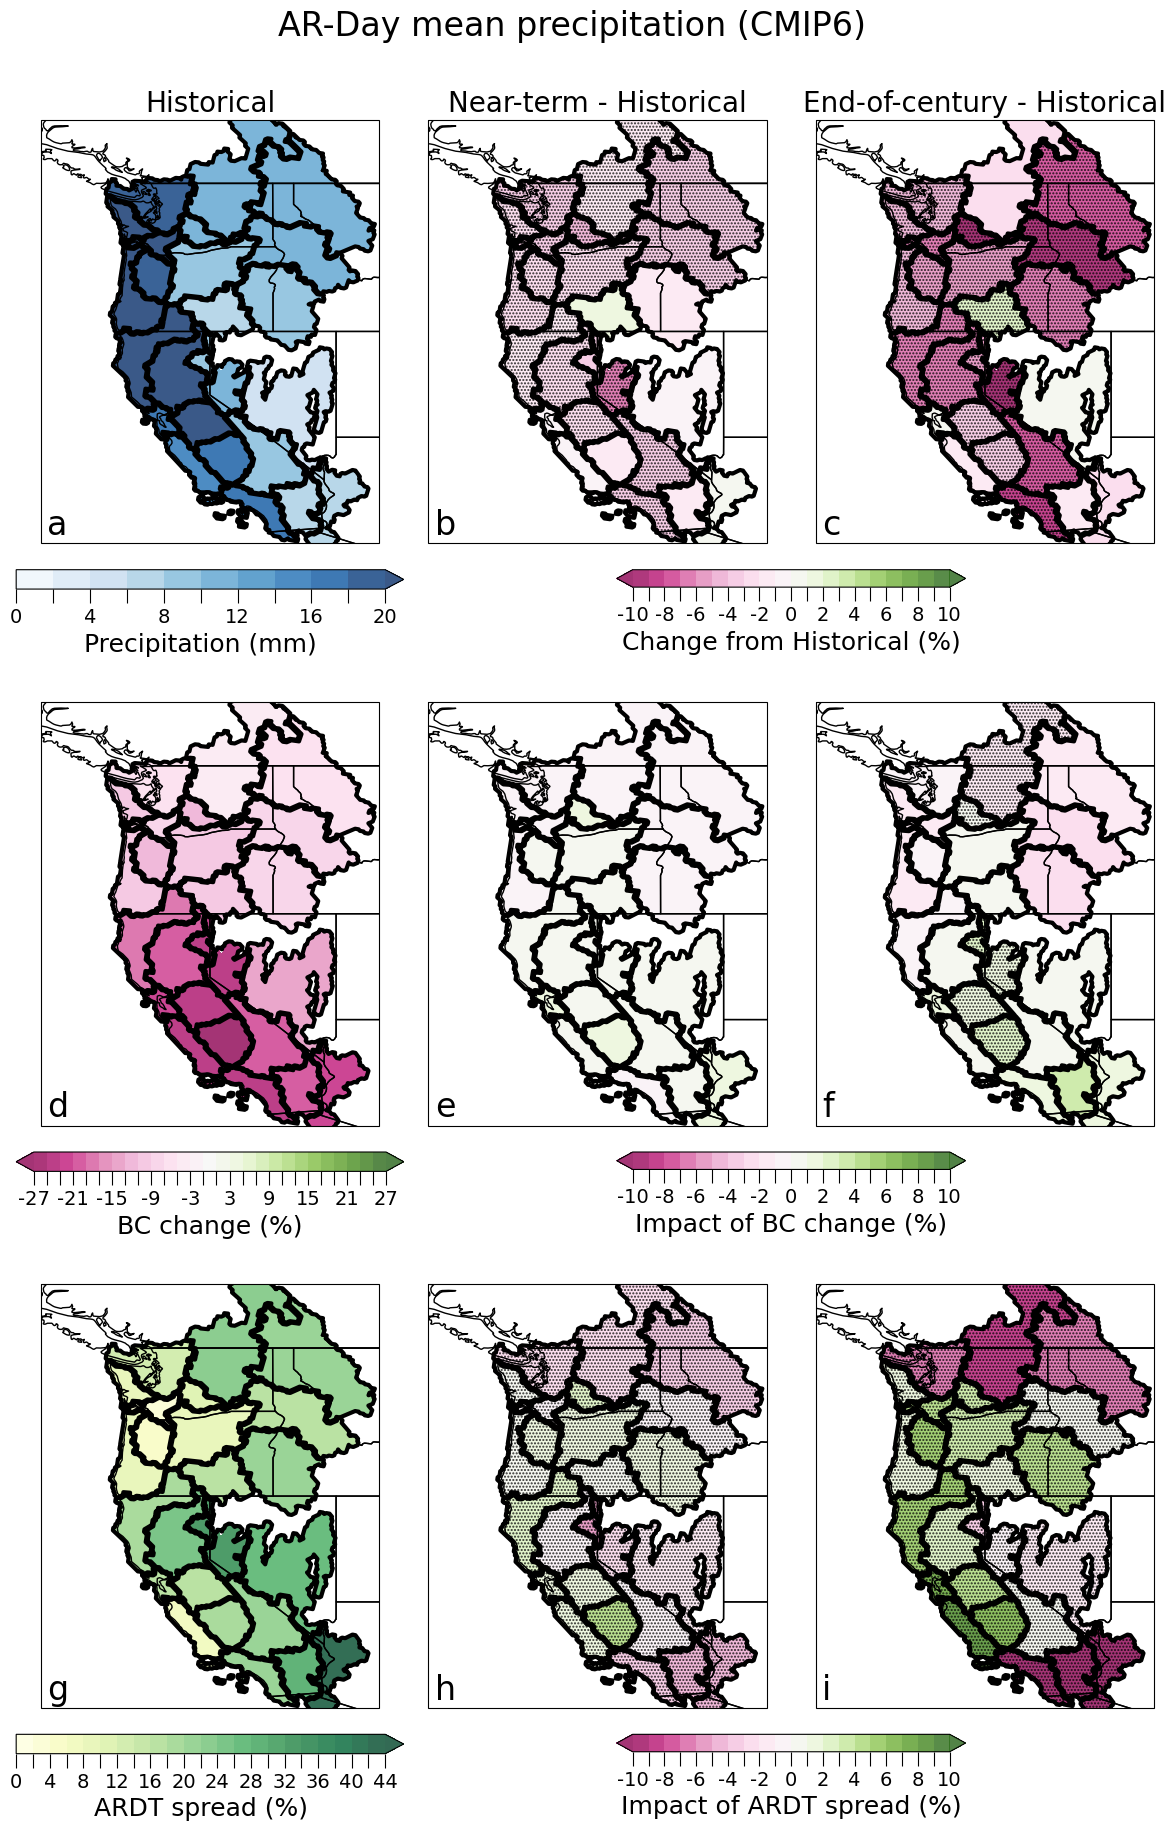

In [8]:
fig1, ax1 = fm.make_plots(bounds, 3, 3, figtitle="AR-Day mean precipitation (CMIP6)", wpad=-0.5, hpad=0.1, adjusty=0.93, titlesize=24)

alpha=0.05
n_tests = len(wus_db)
rejectif = alpha/n_tests

for i in range(9):
    if i==0:
        color = prec_color
        max_val = round(np.nanmax(plot_layouts[0].data), -1)
        ranges = np.arange(0, max_val+1, max_val//10)
        extends = 'max'
    elif i==3:
        color = diff_color_signed
        max_val = round(np.nanmax(np.abs(plot_layouts[3].data)), 0)
        ranges = np.arange(-max_val, max_val+1, 2)
        extends = 'both'
    elif i==6:
        color = diff_color_unsigned
        max_val = round(np.nanmax(plot_layouts[6].data), 0)
        ranges = np.arange(0, max_val+1, 2)
        extends = 'max'
    else:
        color = diff_color_signed
        ranges = np.arange(-10, 11, 1)
        extends = 'both'

    
    this_sig_testing = sig_testing[i]
    sig_testing_binary = xa.where(this_sig_testing < rejectif, 1, 0)


    fplot = fm.plot_var(fig1, ax1[i//3, i%3], [plot_layouts[i].XLONG, plot_layouts[i].XLAT, plot_layouts[i].data], 'contourf', prange=ranges, extend=extends, cmap=color)
    stip = fm.plot_var(fig1, ax1[i//3, i%3], [sig_testing_binary.XLONG, sig_testing_binary.XLAT, sig_testing_binary.data], 'contourf', prange=[0.5, 1.5])
    stip.set_facecolor('none')
    stip.set_edgecolor('black')
    stip.set_hatch('.....')
    stip.set_linewidth(0)
    
    if i==0:
        fm.make_colorbar(fig1, ax1[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax1[i//3, i%3], label='Precipitation (mm)', shrink=0.5, pad=0.05)
    elif i == 3:
        fm.make_colorbar(fig1, ax1[1, 0], fplot, 'int', 'horizontal', ranges, hide=3, cbar_axes=ax1[1, 0], label='BC change (%)', shrink=0.5, pad=0.05)
    elif i == 6:
        fm.make_colorbar(fig1, ax1[2, 0], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax1[2, 0], label='ARDT spread (%)', shrink=0.5, pad=0.05)
    elif i == 4:
        fm.make_colorbar(fig1, ax1[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax1[i//3, i%3:i%3+2], label='Impact of BC change (%)', shrink=0.3, pad=0.05)
    elif i == 7:
        fm.make_colorbar(fig1, ax1[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax1[i//3, i%3:i%3+2], label='Impact of ARDT spread (%)', shrink=0.3, pad=0.05)
    elif i == 1:
        fm.make_colorbar(fig1, ax1[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax1[i//3, i%3:i%3+2], label='Change from Historical (%)', shrink=0.3, pad=0.05)
    
for j in range(3):
    ax1[j, 0].set_ylabel(ytitles[j], fontsize=20)
    ax1[0, j].set_title(xtitles[j], fontsize=20)


for idx, row in wus_db.iterrows():
    huc4 = ds_region.where(rmask == idx, 0)
    for i in range(9):
        cplot = fm.plot_var(fig1, ax1[i // 3, i % 3], [huc4.XLONG, huc4.XLAT, huc4.data], 'contour', crange=np.arange(0,1))
        cplot.set_linewidth(3)

for i in range(9):
    ax1[i//3, i%3].text(0.02, 0.02, string.ascii_lowercase[i], fontsize=24, transform=ax1[i//3, i%3].transAxes)

fig1.set_size_inches(20, 22)
fig1.canvas.draw()

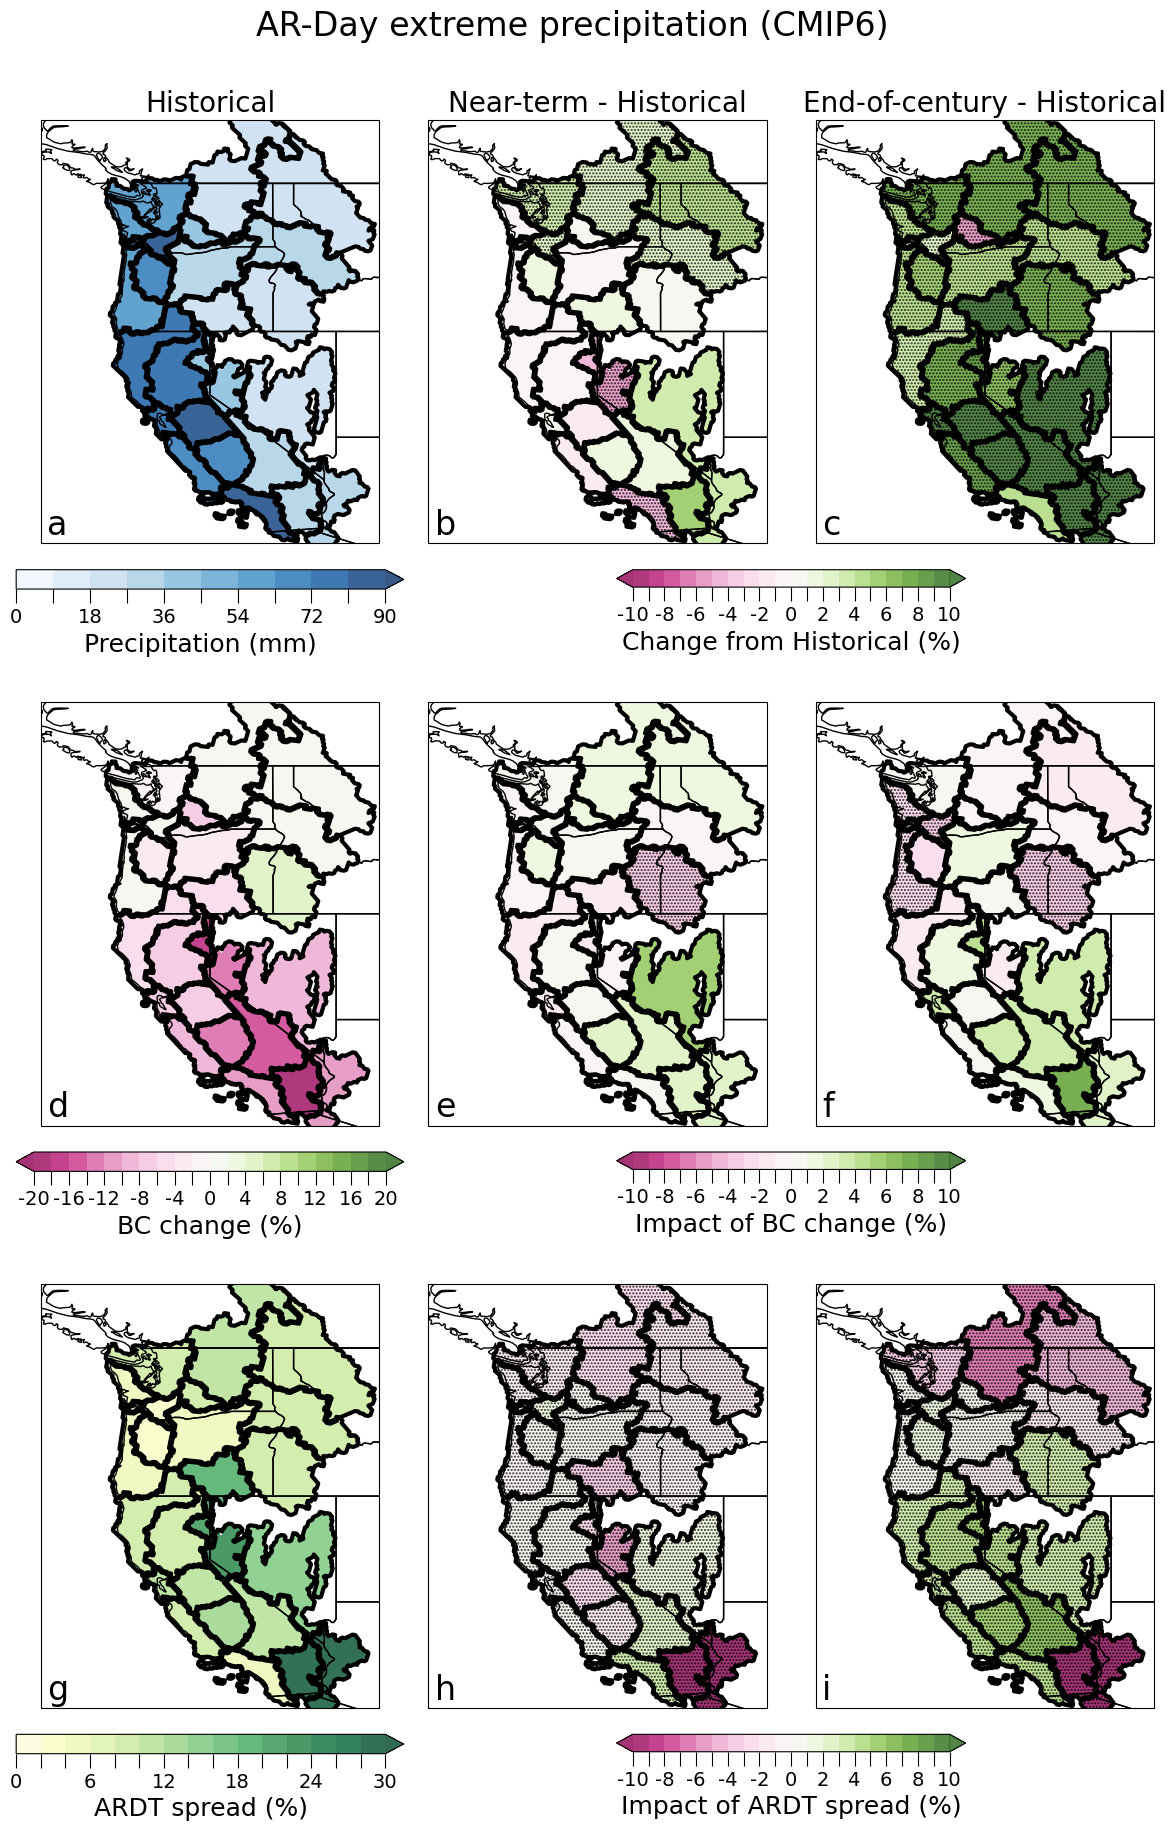

In [9]:
fig2, ax2 = fm.make_plots(bounds, 3, 3, figtitle="AR-Day extreme precipitation (CMIP6)", wpad=-0.5, hpad=0.1, adjusty=0.93, titlesize=24)

alpha=0.05
n_tests = len(wus_db)
rejectif = alpha/n_tests

for i in range(9):
    if i==0:
        color = prec_color
        max_val = round(np.nanmax(plot_layouts[0+9].data), -1)
        ranges = np.arange(0, max_val+1, max_val//10)
        extends = 'max'
    elif i==3:
        color = diff_color_signed
        max_val = round(np.nanmax(np.abs(plot_layouts[3+9].data)), 0)
        ranges = np.arange(-max_val-1, max_val+3, 2)
        extends = 'both'
    elif i==6:
        color = diff_color_unsigned
        max_val = round(np.nanmax(plot_layouts[6+9].data), 0)
        ranges = np.arange(0, max_val+1, 2)
        extends = 'max'
    else:
        color = diff_color_signed
        ranges = np.arange(-10, 11, 1)
        extends = 'both'


    this_sig_testing = sig_testing[i+9]
    sig_testing_binary = xa.where(this_sig_testing < rejectif, 1, 0)
    fplot = fm.plot_var(fig2, ax2[i//3, i%3], [plot_layouts[i+9].XLONG, plot_layouts[i+9].XLAT, plot_layouts[i+9].data], 'contourf', prange=ranges, extend=extends, cmap=color)
    stip = fm.plot_var(fig2, ax2[i//3, i%3], [sig_testing_binary.XLONG, sig_testing_binary.XLAT, sig_testing_binary.data], 'contourf', prange=[0.5, 1.5])
    stip.set_facecolor('none')
    stip.set_edgecolor('black')
    stip.set_hatch('.....')
    stip.set_linewidth(0)
    
    if i==0:
        fm.make_colorbar(fig2, ax2[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax2[i//3, i%3], label='Precipitation (mm)', shrink=0.5, pad=0.05)
    elif i == 3:
        fm.make_colorbar(fig2, ax2[1, 0], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax2[1, 0], label='BC change (%)', shrink=0.5, pad=0.05)
    elif i == 6:
        fm.make_colorbar(fig2, ax2[2, 0], fplot, 'int', 'horizontal', ranges, hide=3, cbar_axes=ax2[2, 0], label='ARDT spread (%)', shrink=0.5, pad=0.05)
    elif i == 4:
        fm.make_colorbar(fig2, ax2[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax2[i//3, i%3:i%3+2], label='Impact of BC change (%)', shrink=0.3, pad=0.05)
    elif i == 7:
        fm.make_colorbar(fig2, ax2[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax2[i//3, i%3:i%3+2], label='Impact of ARDT spread (%)', shrink=0.3, pad=0.05)
    elif i == 1:
        fm.make_colorbar(fig2, ax2[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax2[i//3, i%3:i%3+2], label='Change from Historical (%)', shrink=0.3, pad=0.05)
        
for j in range(3):
    ax2[j, 0].set_ylabel(ytitles[j], fontsize=20)
    ax2[0, j].set_title(xtitles[j], fontsize=20)


for idx, row in wus_db.iterrows():
    huc4 = ds_region.where(rmask == idx, 0)
    for i in range(9):
        cplot = fm.plot_var(fig2, ax2[i // 3, i % 3], [huc4.XLONG, huc4.XLAT, huc4.data], 'contour', crange=np.arange(0,1))
        cplot.set_linewidth(3)

for i in range(9):
    ax2[i//3, i%3].text(0.02, 0.02, string.ascii_lowercase[i], fontsize=24, transform=ax2[i//3, i%3].transAxes)

fig2.set_size_inches(20, 22)
fig2.canvas.draw()

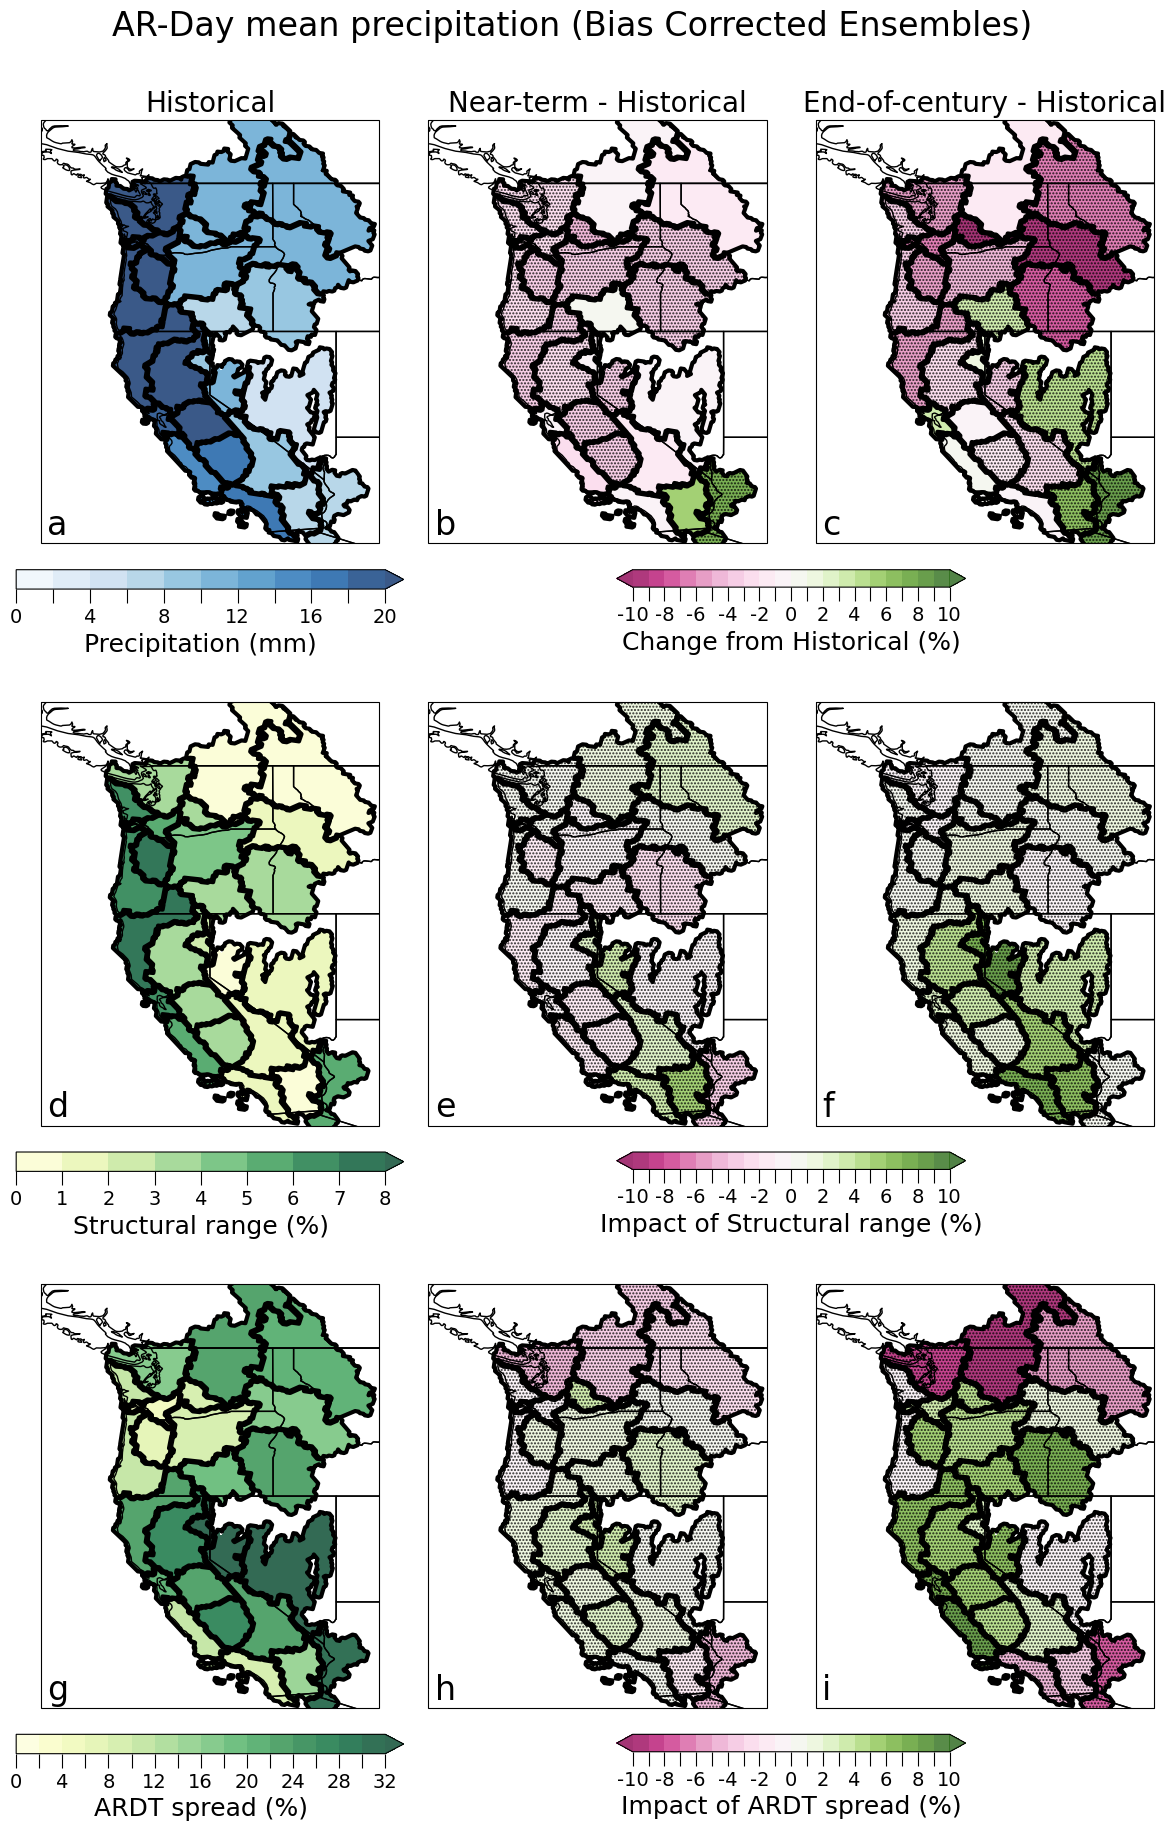

In [10]:
fig3, ax3 = fm.make_plots(bounds, 3, 3, figtitle="AR-Day mean precipitation (Bias Corrected Ensembles)", wpad=-0.5, hpad=0.1, adjusty=0.93, titlesize=24)

alpha=0.05
n_tests = len(wus_db)
rejectif = alpha/n_tests

for i in range(9):
    if i==0:
        color = prec_color
        max_val = round(np.nanmax(plot_layouts[0+18].data), -1)
        ranges = np.arange(0, max_val+1, max_val//10)
        extends = 'max'
    elif i==3:
        color = diff_color_unsigned
        max_val = round(np.nanmax(np.abs(plot_layouts[3+18].data)), 0)
        ranges = np.arange(0, max_val+1, 1)
        extends = 'max'
    elif i==6:
        color = diff_color_unsigned
        max_val = round(np.nanmax(plot_layouts[6+18].data), 0)
        ranges = np.arange(0, max_val, 2)
        extends = 'max'
    else:
        color = diff_color_signed
        ranges = np.arange(-10, 11, 1)
        extends = 'both'

    this_sig_testing = sig_testing[i+18]
    sig_testing_binary = xa.where(this_sig_testing < rejectif, 1, 0)
    fplot = fm.plot_var(fig3, ax3[i//3, i%3], [plot_layouts[i+18].XLONG, plot_layouts[i+18].XLAT, plot_layouts[i+18].data], 'contourf', prange=ranges, extend=extends, cmap=color)
    stip = fm.plot_var(fig3, ax3[i//3, i%3], [sig_testing_binary.XLONG, sig_testing_binary.XLAT, sig_testing_binary.data], 'contourf', prange=[0.5, 1.5])
    stip.set_facecolor('none')
    stip.set_edgecolor('black')
    stip.set_hatch('.....')
    stip.set_linewidth(0)
    
    if i==0:
        fm.make_colorbar(fig3, ax3[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax3[i//3, i%3], label='Precipitation (mm)', shrink=0.5, pad=0.05)
    elif i == 3:
        fm.make_colorbar(fig3, ax3[1, 0], fplot, 'int', 'horizontal', ranges, hide=1, cbar_axes=ax3[1, 0], label='Structural range (%)', shrink=0.5, pad=0.05)
    elif i == 6:
        fm.make_colorbar(fig3, ax3[2, 0], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax3[2, 0], label='ARDT spread (%)', shrink=0.5, pad=0.05)
    elif i == 4:
        fm.make_colorbar(fig3, ax3[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax3[i//3, i%3:i%3+2], label='Impact of Structural range (%)', shrink=0.3, pad=0.05)
    elif i == 7:
        fm.make_colorbar(fig3, ax3[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax3[i//3, i%3:i%3+2], label='Impact of ARDT spread (%)', shrink=0.3, pad=0.05)
    elif i == 1:
        fm.make_colorbar(fig3, ax3[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax3[i//3, i%3:i%3+2], label='Change from Historical (%)', shrink=0.3, pad=0.05)
    
for j in range(3):
    ax3[j, 0].set_ylabel(ytitles[j], fontsize=20)
    ax3[0, j].set_title(xtitles[j], fontsize=20)


for idx, row in wus_db.iterrows():
    huc4 = ds_region.where(rmask == idx, 0)
    for i in range(9):
        cplot = fm.plot_var(fig3, ax3[i // 3, i % 3], [huc4.XLONG, huc4.XLAT, huc4.data], 'contour', crange=np.arange(0,1))
        cplot.set_linewidth(3)

for i in range(9):
    ax3[i//3, i%3].text(0.02, 0.02, string.ascii_lowercase[i], fontsize=24, transform=ax3[i//3, i%3].transAxes)

fig3.set_size_inches(20, 22)
fig3.canvas.draw()

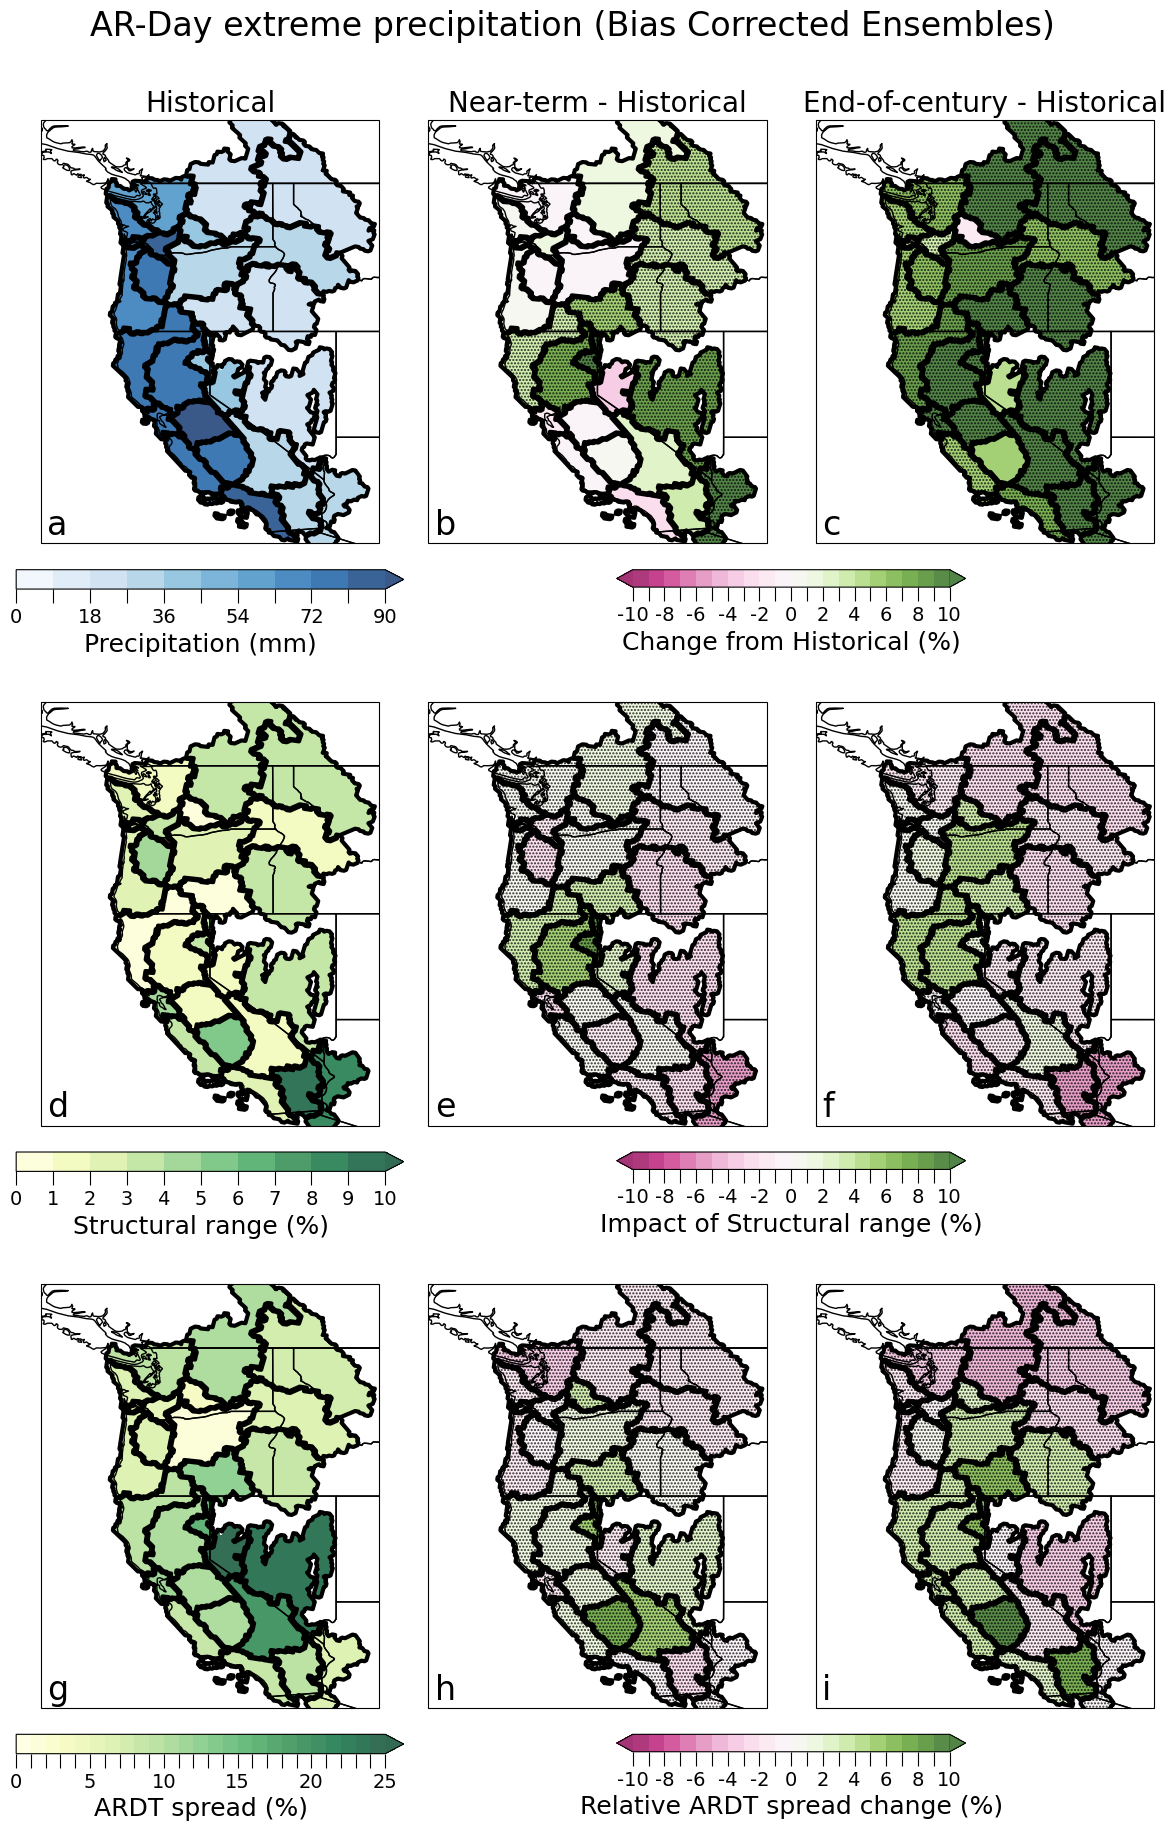

In [11]:
fig4, ax4 = fm.make_plots(bounds, 3, 3, figtitle="AR-Day extreme precipitation (Bias Corrected Ensembles)", wpad=-0.5, hpad=0.1, adjusty=0.93, titlesize=24)

alpha=0.05
n_tests = len(wus_db)
rejectif = alpha/n_tests

for i in range(9):
    if i==0:
        color = prec_color
        max_val = round(np.nanmax(plot_layouts[0+27].data), -1)
        ranges = np.arange(0, max_val+1, max_val//10)
        extends = 'max'
    elif i==3:
        color = diff_color_unsigned
        max_val = round(np.nanmax(np.abs(plot_layouts[3+27].data)), 0)
        ranges = np.arange(0, max_val+1, 1)
        extends = 'max'
    elif i==6:
        color = diff_color_unsigned
        max_val = round(np.nanmax(plot_layouts[6+27].data), 0)
        ranges = np.arange(0, max_val+2, 1)
        extends = 'max'
    else:
        color = diff_color_signed
        ranges = np.arange(-10, 11, 1)
        extends = 'both'

    this_sig_testing = sig_testing[i+27]
    sig_testing_binary = xa.where(this_sig_testing < rejectif, 1, 0)
    fplot = fm.plot_var(fig4, ax4[i//3, i%3], [plot_layouts[i+27].XLONG, plot_layouts[i+27].XLAT, plot_layouts[i+27].data], 'contourf', prange=ranges, extend=extends, cmap=color)
    stip = fm.plot_var(fig4, ax4[i//3, i%3], [sig_testing_binary.XLONG, sig_testing_binary.XLAT, sig_testing_binary.data], 'contourf', prange=[0.5, 1.5])
    stip.set_facecolor('none')
    stip.set_edgecolor('black')
    stip.set_hatch('.....')
    stip.set_linewidth(0)
    
    if i==0:
        fm.make_colorbar(fig4, ax4[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax4[i//3, i%3], label='Precipitation (mm)', shrink=0.5, pad=0.05)
    elif i == 3:
        fm.make_colorbar(fig4, ax4[1, 0], fplot, 'int', 'horizontal', ranges, hide=1, cbar_axes=ax4[1, 0], label='Structural range (%)', shrink=0.5, pad=0.05)
    elif i == 6:
        fm.make_colorbar(fig4, ax4[2, 0], fplot, 'int', 'horizontal', ranges, hide=5, cbar_axes=ax4[2, 0], label='ARDT spread (%)', shrink=0.5, pad=0.05)
    elif i == 4:
        fm.make_colorbar(fig4, ax4[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax4[i//3, i%3:i%3+2], label='Impact of Structural range (%)', shrink=0.3, pad=0.05)
    elif i == 7:
        fm.make_colorbar(fig4, ax4[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax4[i//3, i%3:i%3+2], label='Impact of ARDT spread (%)', shrink=0.3, pad=0.05)
    elif i == 1:
        fm.make_colorbar(fig4, ax4[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax4[i//3, i%3:i%3+2], label='Change from Historical (%)', shrink=0.3, pad=0.05)    
for j in range(3):
    ax4[j, 0].set_ylabel(ytitles[j], fontsize=20)
    ax4[0, j].set_title(xtitles[j], fontsize=20)


for idx, row in wus_db.iterrows():
    huc4 = ds_region.where(rmask == idx, 0)
    for i in range(9):
        cplot = fm.plot_var(fig4, ax4[i // 3, i % 3], [huc4.XLONG, huc4.XLAT, huc4.data], 'contour', crange=np.arange(0,1))
        cplot.set_linewidth(3)

for i in range(9):
    ax4[i//3, i%3].text(0.02, 0.02, string.ascii_lowercase[i], fontsize=24, transform=ax4[i//3, i%3].transAxes)

fig4.set_size_inches(20, 22)
fig4.canvas.draw()

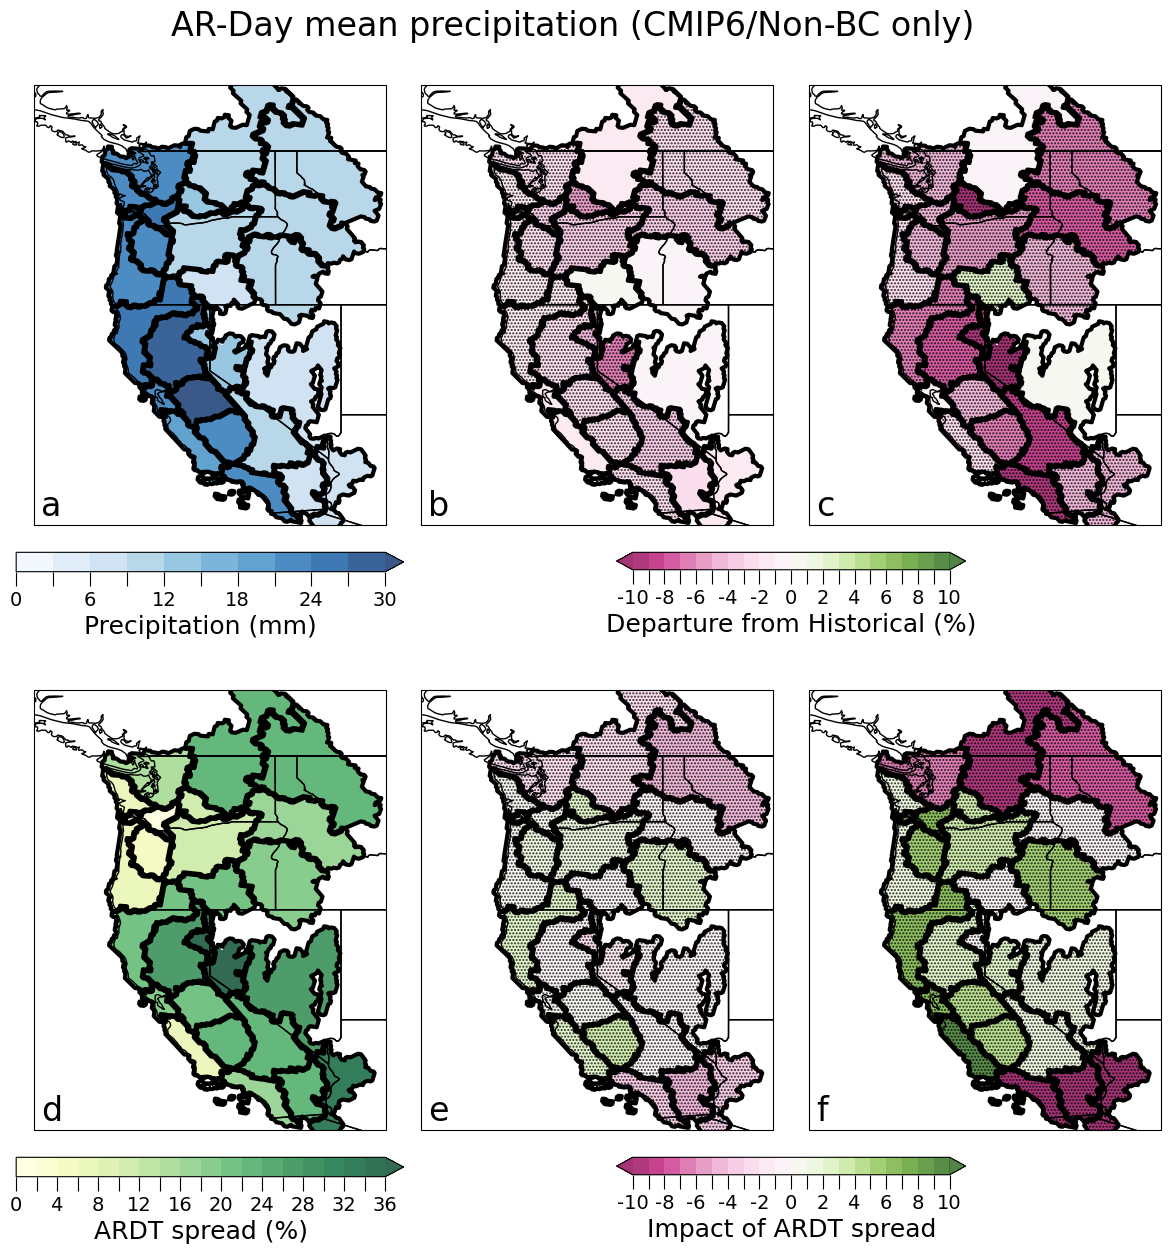

In [12]:
fig5, ax5 = fm.make_plots(bounds, 2, 3, figtitle="AR-Day mean precipitation (CMIP6/Non-BC only)", wpad=-0.5, hpad=0.1, adjusty=0.93, titlesize=24)

alpha=0.05
n_tests = len(wus_db)
rejectif = alpha/n_tests

for i in range(6):
    if i==0:
        color = prec_color
        max_val = round(np.nanmax(plot_layouts_supp[0].data), -1)
        ranges = np.arange(0, max_val+1, max_val//10)
        extends = 'max'
    elif i==3:
        color = diff_color_unsigned
        max_val = round(np.nanmax(plot_layouts_supp[3].data), 0)
        ranges = np.arange(0, max_val-1, 2)
        extends = 'max'
    else:
        color = diff_color_signed
        ranges = np.arange(-10, 11, 1)
        extends = 'both'

    
    this_sig_testing_supp = sig_testing_supp[i]
    sig_testing_binary_supp = xa.where(this_sig_testing_supp < rejectif, 1, 0)


    fplot = fm.plot_var(fig5, ax5[i//3, i%3], [plot_layouts_supp[i].XLONG, plot_layouts_supp[i].XLAT, plot_layouts_supp[i].data], 'contourf', prange=ranges, extend=extends, cmap=color)
    stip = fm.plot_var(fig5, ax5[i//3, i%3], [sig_testing_binary_supp.XLONG, sig_testing_binary_supp.XLAT, sig_testing_binary_supp.data], 'contourf', prange=[0.5, 1.5])
    stip.set_facecolor('none')
    stip.set_edgecolor('black')
    stip.set_hatch('.....')
    stip.set_linewidth(0)
    
    if i==0:
        fm.make_colorbar(fig5, ax5[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax5[i//3, i%3], label='Precipitation (mm)', shrink=0.5, pad=0.05)
    elif i == 3:
        fm.make_colorbar(fig5, ax5[1, 0], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax5[1, 0], label='ARDT spread (%)', shrink=0.5, pad=0.05)
    elif i == 4:
        fm.make_colorbar(fig5, ax5[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax5[i//3, i%3:i%3+2], label='Impact of ARDT spread', shrink=0.3, pad=0.05)
    elif i == 1:
        fm.make_colorbar(fig5, ax5[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax5[i//3, i%3:i%3+2], label='Departure from Historical (%)', shrink=0.3, pad=0.05)
    
for j in range(3):
    ax1[j, 0].set_ylabel(ytitles[j], fontsize=20)


for idx, row in wus_db.iterrows():
    huc4 = ds_region.where(rmask == idx, 0)
    for i in range(6):
        cplot = fm.plot_var(fig5, ax5[i // 3, i % 3], [huc4.XLONG, huc4.XLAT, huc4.data], 'contour', crange=np.arange(0,1))
        cplot.set_linewidth(3)

for i in range(6):
    ax5[i//3, i%3].text(0.02, 0.02, string.ascii_lowercase[i], fontsize=24, transform=ax5[i//3, i%3].transAxes)

fig5.set_size_inches(20, 15)
fig5.canvas.draw()

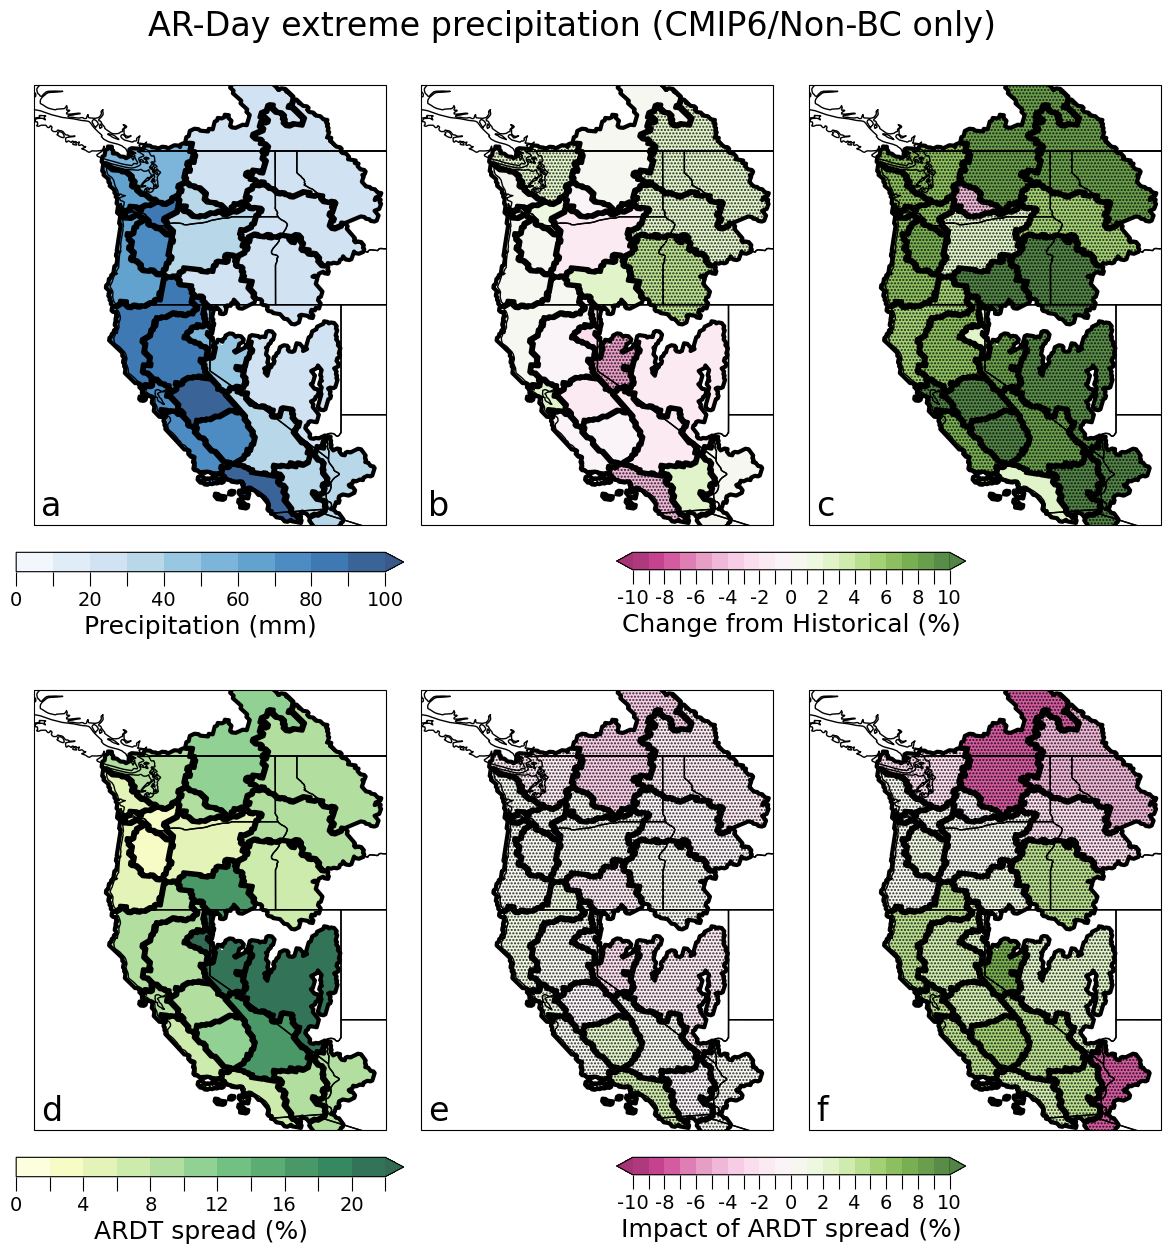

In [13]:
fig6, ax6 = fm.make_plots(bounds, 2, 3, figtitle="AR-Day extreme precipitation (CMIP6/Non-BC only)", wpad=-0.5, hpad=0.1, adjusty=0.93, titlesize=24)

alpha=0.05
n_tests = len(wus_db)
rejectif = alpha/n_tests

for i in range(6):
    if i==0:
        color = prec_color
        max_val = round(np.nanmax(plot_layouts_supp[0+6].data), -1)
        ranges = np.arange(0, max_val+1, max_val//10)
        extends = 'max'
    elif i==3:
        color = diff_color_unsigned
        max_val = round(np.nanmax(plot_layouts_supp[3+6].data), 0)
        ranges = np.arange(0, max_val-1, 2)
        extends = 'max'
    else:
        color = diff_color_signed
        ranges = np.arange(-10, 11, 1)
        extends = 'both'

    
    this_sig_testing_supp = sig_testing_supp[i+6]
    sig_testing_binary_supp = xa.where(this_sig_testing_supp < rejectif, 1, 0)


    fplot = fm.plot_var(fig6, ax6[i//3, i%3], [plot_layouts_supp[i+6].XLONG, plot_layouts_supp[i+6].XLAT, plot_layouts_supp[i+6].data], 'contourf', prange=ranges, extend=extends, cmap=color)
    stip = fm.plot_var(fig6, ax6[i//3, i%3], [sig_testing_binary_supp.XLONG, sig_testing_binary_supp.XLAT, sig_testing_binary_supp.data], 'contourf', prange=[0.5, 1.5])
    stip.set_facecolor('none')
    stip.set_edgecolor('black')
    stip.set_hatch('.....')
    stip.set_linewidth(0)
    
    if i==0:
        fm.make_colorbar(fig6, ax6[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax6[i//3, i%3], label='Precipitation (mm)', shrink=0.5, pad=0.05)
    elif i == 3:
        fm.make_colorbar(fig6, ax6[1, 0], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax6[1, 0], label='ARDT spread (%)', shrink=0.5, pad=0.05)
    elif i == 4:
        fm.make_colorbar(fig6, ax6[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax6[i//3, i%3:i%3+2], label='Impact of ARDT spread (%)', shrink=0.3, pad=0.05)
    elif i == 1:
        fm.make_colorbar(fig6, ax6[i//3, i%3], fplot, 'int', 'horizontal', ranges, hide=2, cbar_axes=ax6[i//3, i%3:i%3+2], label='Change from Historical (%)', shrink=0.3, pad=0.05)
    
for j in range(3):
    ax1[j, 0].set_ylabel(ytitles[j], fontsize=20)


for idx, row in wus_db.iterrows():
    huc4 = ds_region.where(rmask == idx, 0)
    for i in range(6):
        cplot = fm.plot_var(fig6, ax6[i // 3, i % 3], [huc4.XLONG, huc4.XLAT, huc4.data], 'contour', crange=np.arange(0,1))
        cplot.set_linewidth(3)

for i in range(6):
    ax6[i//3, i%3].text(0.02, 0.02, string.ascii_lowercase[i], fontsize=24, transform=ax6[i//3, i%3].transAxes)

fig6.set_size_inches(20, 15)
fig6.canvas.draw()

In [14]:
fm.save(fig1, '/glade/work/tcorrie/ARdata/Figures/watersheds/map-plots/map_plot_diffs_prec_mean_cmip6.png')
fm.save(fig2, '/glade/work/tcorrie/ARdata/Figures/watersheds/map-plots/map_plot_diffs_prec_mean_extreme_cmip6.png')
fm.save(fig3, '/glade/work/tcorrie/ARdata/Figures/watersheds/map-plots/map_plot_diffs_prec_mean_bced.png')
fm.save(fig4, '/glade/work/tcorrie/ARdata/Figures/watersheds/map-plots/map_plot_diffs_prec_mean_extreme_bced.png')
fm.save(fig5, '/glade/work/tcorrie/ARdata/Figures/watersheds/map-plots/map_plot_diffs_prec_mean_cmip6_nonbc.png')
fm.save(fig6, '/glade/work/tcorrie/ARdata/Figures/watersheds/map-plots/map_plot_diffs_prec_mean_extreme_cmip6_nonbc.png')

In [15]:
fm.save(fig1, '/glade/work/tcorrie/ARdata/Figures/JoC/map_plot_diffs_prec_mean_cmip6.png')
fm.save(fig2, '/glade/work/tcorrie/ARdata/Figures/JoC/map_plot_diffs_prec_mean_extreme_cmip6.png')
fm.save(fig3, '/glade/work/tcorrie/ARdata/Figures/JoC/map_plot_diffs_prec_mean_bced.png')
fm.save(fig4, '/glade/work/tcorrie/ARdata/Figures/JoC/map_plot_diffs_prec_mean_extreme_bced.png')
fm.save(fig5, '/glade/work/tcorrie/ARdata/Figures/JoC/map_plot_diffs_prec_mean_cmip6_nonbc.png')
fm.save(fig6, '/glade/work/tcorrie/ARdata/Figures/JoC/map_plot_diffs_prec_mean_extreme_cmip6_nonbc.png')